# DeFi Exploit-Precursor Feasibility Study (v4) — can yield/TVL data predict exploits?

**Status of claims.** This notebook is a *leakage-safe, pre-registered feasibility study*, not a "risk engine that works". It reports whatever the data supports, including a null result. All numbers in the write-up must be copied from the artifacts this notebook writes (`artifacts/v4/`), never typed by hand.

**Pre-registered design (frozen before looking at test results; edit only via a new version):**

| Item | Choice |
|---|---|
| Question | Do point-in-time yield/TVL features raise the chance of an alert in the 7 days before a hack, *above what the same project's ordinary 7-day windows produce*? |
| Incidents | Only categories that can plausibly leave a yield/TVL trace (key compromise, phishing, DNS/front-end, spoofing etc. excluded by `EXCLUDE_TECHNIQUE_REGEX` / `EXCLUDE_CLASSIFICATIONS`). All-category run is a *sensitivity* analysis. |
| Labels | Pool-level: a pool is positive only if its TVL actually fell ≥ `POOL_IMPACT_MIN` within `POST_DAYS` after the event. Unaffected/immature/non-detectable pre-windows are *quarantined*, never counted as negatives. |
| Evaluation | Expanding-window walk-forward, `N_FOLDS` contiguous test blocks; thresholds recalibrated per fold on the validation block immediately before the test block; purge gap ≥ label horizon. |
| Unit of inference | The **incident** (one vote per hack), vs. a same-project placebo of ordinary windows. Row-level AUC/PR-AUC reported with project-cluster bootstrap CIs, never alone. |
| Primary hypothesis | `model` arm (Isolation Forest ∪ supervised classifier, rules excluded) detection rate > placebo. Holm-corrected over all arms. |
| Arms reported separately | `rules`, `iforest`, `clf`, `model`, `combined`, plus single-feature baselines. |
| Skill is claimed only if | Holm-adjusted p < 0.05 **and** lift CI excludes 0 **and** row-level ROC-AUC CI > 0.5 **and** PR-AUC CI > base rate. Otherwise: negative result. |

**What changed from v3** (review findings addressed): walk-forward multi-fold evaluation (more than ~12 incidents count); pool-level + category-filtered labels; `log_tvl` excluded by default with ablation; rank feature replaced by stable-universe percentile and zero-APY rows removed from the model universe; nested time-ordered model selection (logistic regression vs. gradient boosting); rules and model evaluated separately with CIs and exact Poisson-binomial placebo p-values; detection and placebo both measured at project level (no Aave-style 50-pool domination); fuzzy review queue hardened; `summarize_run` counters fixed; replay naive baseline no longer gets forced exits for free; random-gate placebo replay; stale prose and debug cells removed; clean-kernel runnable.

## 1. Configuration (cache-first, network off by default)

In [1]:
from __future__ import annotations
import copy, functools, hashlib, json, platform, re, sys, time, warnings
from collections import defaultdict
from dataclasses import dataclass, replace, asdict
from difflib import SequenceMatcher
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer

try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore", category=FutureWarning)


@dataclass
class Config:
    # ---- data source guards ----
    USE_REAL_DATA: bool = True
    ALLOW_NETWORK: bool = True          # cache-first. Set True ONCE to populate artifacts/raw, then back to False.
    MAX_POOLS: int = 600
    MIN_TVL_FETCH: float = 1_000_000
    REQUEST_DELAY: float = 0.25
    MAX_REQUESTS: int = 900
    FORCE_INCLUDE_HACKED: bool = True
    EXTRA_HACKED_POOLS: int = 150
    MIN_HISTORY_DAYS: int = 45
    APY_SANITY_MAX: float = 10_000.0
    ARTIFACT_DIR: str = "artifacts"
    SEED: int = 42
    # ---- synthetic universe (tests / rehearsal only) ----
    N_PROJECTS: int = 40
    DAYS: int = 540
    N_INCIDENTS: int = 16
    # ---- features ----
    EXCLUDE_FEATURES: tuple = ("log_tvl",)   # size is a selection proxy; re-added only in the ablation
    DROP_ZERO_APY: bool = True               # inactive/zero-APY pools are not an investable universe (regime artifact in v3)
    STABLE_MIN_AGE: int = 60                 # cross-sectional APY percentile is taken within a stable universe
    STABLE_MIN_TVL: float = 1_000_000
    MIN_POOLS_PER_DAY: int = 30              # drop the sparse early period (6 pools) that distorts regimes
    # ---- labels ----
    LOOKAHEAD_DAYS: int = 7
    COOLDOWN_DAYS: int = 30
    POST_DAYS: int = 7
    POOL_LEVEL_LABEL: bool = True
    POOL_IMPACT_MIN: float = 0.20            # pool TVL must fall >=20% within POST_DAYS to count as a victim pool
    EXCLUDE_TECHNIQUE_REGEX: str = (r"phish|private.?key|key.?compromis|compromised.?key|leaked|social.?engineer|"
                                    r"dns|domain|front.?end|spoof|supply.?chain|malware|credential|insider|seed.?phrase")
    EXCLUDE_CLASSIFICATIONS: tuple = ("infrastructure", "cefi")
    INCLUDE_UNCLASSIFIED: bool = False
    FUZZY_CUTOFF: float = 0.85
    # ---- walk-forward ----
    N_FOLDS: int = 5
    MIN_TRAIN_DAYS: int = 365
    VAL_DAYS: int = 90
    PURGE_DAYS: int = 8                      # must be >= LOOKAHEAD_DAYS
    # ---- models ----
    MIN_POS_ROWS: int = 30
    MIN_POS_INCIDENTS: int = 5
    INNER_MIN_INC: int = 3
    INCIDENT_WEIGHT_FRAC: float = 0.02
    CLF_MAX_NEG: int = 150_000
    BLOCK_FPR: float = 0.005
    SIM_FPR: float = 0.02
    # ---- evaluation ----
    ALPHA: float = 0.05
    BOOT: int = 100                          # project-cluster bootstrap draws for row-level CIs
    BOOT_INC: int = 5000                     # incident bootstrap draws
    RUN_ABLATIONS: bool = True
    RUN_SENSITIVITY: bool = True
    REPLAY_PLACEBO_RUNS: int = 20
    # ---- hard-rule floor ----
    MAX_APY_PCT: float = 500.0
    MIN_TVL_USD: float = 500_000.0
    MAX_POOL_7D_DRAWDOWN: float = -0.30
    MAX_PROTO_7D_DRAWDOWN: float = -0.25
    # ---- allocation ----
    CAPITAL_USD: float = 1_000_000.0
    REWARD_HAIRCUT: float = 0.5
    APY_RANK_CAP: float = 50.0
    MIN_APY: float = 1.0
    RISK_AVERSION: float = 0.75
    POOL_CAP: float = 0.15
    PROTO_CAP: float = 0.25
    TVL_SHARE_CAP: float = 0.02
    MAX_POSITIONS: int = 20
    # ---- execution / keeper ----
    MIN_TRADE_USD: float = 1_000.0
    REBALANCE_EVERY_DAYS: int = 7
    REBALANCE_HORIZON_DAYS: int = 30
    HURDLE_MULT: float = 2.0
    DEX_DEPTH_USD: float = 100_000_000.0
    DEX_FEE_BPS: float = 30.0
    WITHDRAW_FEE_BPS: float = 5.0
    MAX_MOVE_LOSS_BPS: float = 150.0
    EXPLOIT_LOSS_FRACTION: float = 0.8       # assumption of the paper world, not a measurement


CFG = Config()
assert CFG.PURGE_DAYS >= CFG.LOOKAHEAD_DAYS, "purge gap must cover the label horizon"
ARTIFACTS = Path(CFG.ARTIFACT_DIR); ARTIFACTS.mkdir(exist_ok=True)
OUT = ARTIFACTS / "v4"; OUT.mkdir(exist_ok=True)

ALL_FEATURES = [
    "apy", "log_tvl", "tvl_ret_1", "tvl_ret_7", "tvl_ret_30", "tvl_dd_30",
    "apy_delta_7", "apy_vol_7", "apy_z_30", "apy_ratio_30", "reward_share",
    "apy_xs_stable", "proto_tvl_ret_7", "proto_tvl_dd_30",
]
FEATURES = [f for f in ALL_FEATURES if f not in CFG.EXCLUDE_FEATURES]
ABLATIONS = {
    "primary": FEATURES,
    "with_log_tvl": list(ALL_FEATURES),
    "apy_features_only": ["apy", "apy_delta_7", "apy_vol_7", "apy_z_30", "apy_ratio_30", "reward_share", "apy_xs_stable"],
    "tvl_features_only": ["tvl_ret_1", "tvl_ret_7", "tvl_ret_30", "tvl_dd_30", "proto_tvl_ret_7", "proto_tvl_dd_30"],
}
ARMS = ["rules", "iforest", "clf", "model", "combined", "base_tvl_dd", "base_apy_z"]
print(f"USE_REAL_DATA={CFG.USE_REAL_DATA}  ALLOW_NETWORK={CFG.ALLOW_NETWORK}  features={len(FEATURES)}  excluded={CFG.EXCLUDE_FEATURES}")

USE_REAL_DATA=True  ALLOW_NETWORK=True  features=13  excluded=('log_tvl',)


## 2. Data layer (loader, cache, cleaning, mock-server rehearsal — carried over from v3)

In [2]:
HEADERS = {"User-Agent": "defi-forensic-feasibility/4.0"}


def parse_dates(values: pd.Series) -> pd.Series:
    """Accept unix s, unix ms or ISO strings -> tz-aware UTC."""
    if pd.api.types.is_datetime64_any_dtype(values):
        return pd.to_datetime(values, utc=True)
    numeric = pd.to_numeric(values, errors="coerce")
    if numeric.notna().mean() > 0.8:
        unit = "ms" if numeric.dropna().abs().median() > 1e12 else "s"
        return pd.to_datetime(numeric, unit=unit, utc=True, errors="coerce")
    return pd.to_datetime(values, utc=True, errors="coerce")


def to_day_num(ts: pd.Series) -> np.ndarray:
    """tz-aware timestamps -> integer day number (days since epoch, UTC)."""
    return ts.dt.tz_convert("UTC").dt.tz_localize(None).values.astype("datetime64[D]").astype("int64")


def make_synthetic_universe(cfg: Config):
    rng = np.random.default_rng(cfg.SEED)
    T = cfg.DAYS
    days = pd.date_range("2025-01-01", periods=T, freq="D", tz="UTC")
    symbols = np.array(["USDC", "USDT", "DAI", "WETH", "WBTC", "stETH"])
    projects = [f"proto-{i:02d}" for i in range(cfg.N_PROJECTS)]
    assert cfg.N_INCIDENTS <= cfg.N_PROJECTS

    # ---- planted incidents (ground truth lives ONLY here; pipeline never reads it) ----
    ev_days = np.linspace(70, T - 12, cfg.N_INCIDENTS).astype(int) + rng.integers(-4, 5, cfg.N_INCIDENTS)
    ev_days = np.clip(ev_days, 40, T - 10)
    ev_projects = rng.choice(projects, size=cfg.N_INCIDENTS, replace=False)
    spec = {}
    for p, d in zip(ev_projects, ev_days):
        detectable = rng.random() < 0.7
        spec[p] = dict(day=int(d), strength=float(rng.uniform(0.6, 1.5)) if detectable else 0.0,
                       mode=str(rng.choice(["hype", "bleed"])), drop=float(rng.uniform(0.6, 0.95)))

    meta_rows, tvl_l, apy_l, rew_l = [], [], [], []
    t_idx = np.arange(T)
    for p in projects:
        n_pools = int(rng.integers(2, 6))
        proj_walk = np.cumsum(rng.normal(0, 0.02, T))
        proj_mult, apy_mult = np.ones(T), np.ones(T)
        s = spec.get(p)
        if s:
            d, w = s["day"], cfg.LOOKAHEAD_DAYS
            ramp = np.clip((t_idx - (d - w)) / w, 0, 1) * (t_idx < d)
            apy_mult = apy_mult * (1 + 2.5 * s["strength"] * ramp)
            proj_mult = proj_mult * ((1 + 0.15 * s["strength"] * ramp) if s["mode"] == "hype"
                                     else (1 - 0.20 * s["strength"] * ramp))
            post = t_idx >= d
            proj_mult = np.where(post, proj_mult * (1 - s["drop"]), proj_mult)
            apy_mult = np.where(post, 0.3, apy_mult)
        base_tvl = rng.lognormal(18.0, 1.0)
        reward_share = rng.uniform(0.0, 0.7)
        for k in range(n_pools):
            tvl = base_tvl * rng.uniform(0.15, 1.0) * np.exp(proj_walk + np.cumsum(rng.normal(0, 0.01, T))) * proj_mult
            mu = rng.lognormal(1.5, 0.6)
            noise = rng.normal(0, 0.15 * mu + 0.1, T)
            x = np.empty(T); x[0] = mu
            for t in range(1, T):
                x[t] = x[t - 1] + 0.08 * (mu - x[t - 1]) + noise[t]
            x = np.clip(x, 0.05, None)
            if (not s) and rng.random() < 0.3:          # benign spike (false-positive trap)
                b = int(rng.integers(40, T - 5)); x[b:b + 3] *= 3.0
            x = x * apy_mult
            meta_rows.append(dict(pool=f"{p}-pool{k}", project=p, symbol=str(rng.choice(symbols))))
            tvl_l.append(tvl); apy_l.append(x); rew_l.append(x * reward_share)

    meta = pd.DataFrame(meta_rows)
    n = len(meta)
    tvl, apy, rew = np.vstack(tvl_l), np.vstack(apy_l), np.vstack(rew_l)
    ts = pd.to_datetime(np.tile(days.tz_convert(None).values, n), utc=True)
    hist = pd.DataFrame({
        "pool": np.repeat(meta.pool.values, T), "project": np.repeat(meta.project.values, T),
        "symbol": np.repeat(meta.symbol.values, T), "timestamp": ts,
        "tvlUsd": tvl.ravel(), "apy": apy.ravel(), "apyReward": rew.ravel(),
    })
    hist["apyBase"] = hist["apy"] - hist["apyReward"]
    hist = hist.loc[rng.random(len(hist)) > 0.02].reset_index(drop=True)

    # ---- hack feed in DeFiLlama shape ----
    hacks, aliases = [], {}
    for i, (p, sp) in enumerate(spec.items()):
        name = p.replace("-", " ").title()                 # "Proto 03" -> normalises to proto03
        if i == 2:                                         # needs a reviewed alias
            name = f"{p} Finance"; aliases[name] = p
        hacks.append(dict(name=name, date=int(days[sp["day"]].timestamp()), amount=float(sp["drop"] * 1e7), chain="Ethereum", classification="Protocol Logic", technique="Logic Error"))
    for j in range(25):                                    # decoys
        hacks.append(dict(name=f"Unlisted Protocol {j}", date=int(days[int(rng.integers(0, T))].timestamp()), amount=1e6, chain="BSC"))
    hacks.append(dict(name="Proto 99", date=int(days[100].timestamp()), amount=5e5, chain="Ethereum"))
    return hist, hacks, aliases, meta, spec


def normalize_name(s) -> str:
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


class BudgetExceeded(RuntimeError):
    pass


def fetch_real_data(cfg: Config):
    """REAL DeFiLlama loader.

    Cost-safety design (why it is built this way)
    * USE_REAL_DATA must be True.  The network is touched ONLY on a cache miss and ONLY if
      ALLOW_NETWORK is True; otherwise a RuntimeError says exactly what is missing.
      => fetch once, then set ALLOW_NETWORK=False and rerun offline for free.
    * Every response is written to disk before the next call (crash-resumable).
    * MAX_REQUESTS is a hard cap on live calls per run; hitting it keeps the cache and returns a
      PARTIAL universe with a loud warning (never silently).

    Selection-bias design (the hard part of real data)
    * The yields catalogue lists only CURRENTLY listed pools. Pools of exploited protocols are often
      drained/delisted, so a plain "top-N by current TVL" universe contains almost no victims.
      FORCE_INCLUDE_HACKED therefore also fetches every catalogue pool of a hacked project (matched
      through the hack feed's own defillamaId, with name matching as a fallback).
    * Hacks are tied to pools through DeFiLlama ids (protocol id -> slug, parent id -> child slugs),
      because hack display names ("Euler Finance") rarely equal pool project slugs ("euler").
    """
    if not cfg.USE_REAL_DATA:
        raise RuntimeError("Real data disabled. Set CFG.USE_REAL_DATA=True (and ALLOW_NETWORK=True for the first fetch).")
    import requests
    from urllib.parse import quote
    raw = Path(cfg.ARTIFACT_DIR) / "raw"; (raw / "charts").mkdir(parents=True, exist_ok=True)
    stats = dict(live=0, cached=0)

    def get(url, path):
        if path.exists():
            stats["cached"] += 1
            return json.loads(path.read_text(encoding="utf-8"))
        if not cfg.ALLOW_NETWORK:
            raise RuntimeError(f"Cache miss for '{path.name}' and CFG.ALLOW_NETWORK is False. "
                               "Set ALLOW_NETWORK=True once to populate the cache.")
        if stats["live"] >= cfg.MAX_REQUESTS:
            raise BudgetExceeded(f"MAX_REQUESTS={cfg.MAX_REQUESTS} reached; cache kept, rerun to resume or raise the cap.")
        for attempt in range(3):
            try:
                r = requests.get(url, headers=HEADERS, timeout=30); r.raise_for_status(); data = r.json(); break
            except (requests.RequestException, ValueError):
                if attempt == 2: raise
                time.sleep(2 ** attempt)
        stats["live"] += 1
        path.write_text(json.dumps(data), encoding="utf-8"); time.sleep(cfg.REQUEST_DELAY)
        return data

    hacks = get("https://api.llama.fi/hacks", raw / "hacks.json")
    hacks = hacks.get("data", hacks) if isinstance(hacks, dict) else hacks
    protocols = get("https://api.llama.fi/protocols", raw / "protocols.json")
    protocols = protocols.get("protocols", protocols) if isinstance(protocols, dict) else protocols
    id_to_slugs = defaultdict(set)
    for p in protocols:
        if isinstance(p, dict) and p.get("slug"):
            id_to_slugs[str(p.get("id"))].add(p["slug"])
            if p.get("parentProtocol"):
                id_to_slugs[str(p["parentProtocol"])].add(p["slug"])
    for h in hacks:
        key = h.get("defillamaId")
        h["projects_hint"] = sorted(id_to_slugs.get(str(key), [])) if key not in (None, "") else []

    cat = get("https://yields.llama.fi/pools", raw / "pool_catalog.json")
    pools = pd.DataFrame(cat.get("data", cat) if isinstance(cat, dict) else cat)
    pools["tvlUsd"] = pd.to_numeric(pools["tvlUsd"], errors="coerce")
    pools = pools.dropna(subset=["pool", "project"]).drop_duplicates("pool")
    sel = (pools.dropna(subset=["tvlUsd"]).loc[lambda f: f.tvlUsd >= cfg.MIN_TVL_FETCH]
           .sort_values("tvlUsd", ascending=False).head(cfg.MAX_POOLS))
    if cfg.FORCE_INCLUDE_HACKED:
        hinted = {s for h in hacks for s in h.get("projects_hint", [])}
        named = {normalize_name(h.get("name", "")) for h in hacks} - {""}
        mine = pools[pools.project.isin(hinted) | pools.project.map(normalize_name).isin(named)]
        sel = pd.concat([sel, mine.sort_values("tvlUsd", ascending=False).head(cfg.EXTRA_HACKED_POOLS)]).drop_duplicates("pool")

    rows, failed, truncated = [], [], False
    for r in sel.itertuples(index=False):
        try:
            payload = get(f"https://yields.llama.fi/chart/{quote(str(r.pool), safe='')}", raw / "charts" / f"{r.pool}.json")
        except BudgetExceeded as e:
            print("WARNING - PARTIAL UNIVERSE:", e); truncated = True; break
        except requests.RequestException:
            failed.append(str(r.pool)); continue
        obs = payload.get("data", payload) if isinstance(payload, dict) else payload
        sym = str(getattr(r, "symbol", ""))
        rows += [dict(pool=str(r.pool), project=str(r.project), symbol=sym, timestamp=o.get("timestamp"),
                      tvlUsd=o.get("tvlUsd"), apy=o.get("apy"), apyBase=o.get("apyBase"), apyReward=o.get("apyReward"))
                 for o in obs if isinstance(o, dict)]
    hist = pd.DataFrame(rows, columns=["pool", "project", "symbol", "timestamp", "tvlUsd", "apy", "apyBase", "apyReward"])
    meta = sel[["pool", "project"]].assign(symbol=sel["symbol"] if "symbol" in sel else "").astype(str).reset_index(drop=True)
    print(f"real-data loader: live requests={stats['live']} cache hits={stats['cached']} pools={len(sel)} "
          f"(forced hacked-project pools included) failed={len(failed)} truncated={truncated}")
    return hist, hacks, {}, meta, None


def clean_history(h: pd.DataFrame, cfg: Config):
    """Defensive cleaning for messy real payloads. Must be a no-op on the synthetic universe."""
    rep = {"rows_in": len(h)}
    h = h.copy()
    h["timestamp"] = parse_dates(h["timestamp"])
    for c in ("tvlUsd", "apy", "apyBase", "apyReward"):
        h[c] = pd.to_numeric(h[c], errors="coerce") if c in h else np.nan
    bad = h.timestamp.isna() | ~(h.tvlUsd > 0) | h.apy.isna() | ~(h.apy >= 0) | (h.apy > cfg.APY_SANITY_MAX)
    rep["dropped_invalid"] = int(bad.sum()); h = h[~bad]
    h["_day"] = to_day_num(h["timestamp"])
    n0 = len(h)
    h = h.sort_values(["pool", "timestamp"]).drop_duplicates(["pool", "_day"], keep="last")
    rep["dropped_duplicate_days"] = n0 - len(h)
    short = h.groupby("pool")["_day"].transform("nunique") < cfg.MIN_HISTORY_DAYS
    rep["dropped_short_history_pools"] = int(h.loc[short, "pool"].nunique()); h = h[~short]
    rep["rows_out"] = len(h)
    return h.drop(columns="_day").reset_index(drop=True), rep


class _Resp:
    def __init__(self, body): self._b = json.loads(json.dumps(body))
    def raise_for_status(self): pass
    def json(self): return self._b


class MockDefiLlama:
    """Serves DeFiLlama-SHAPED payloads built from the synthetic universe, with the messiness real
    endpoints have. Contains NO real data and makes NO network call; used to rehearse the real-data
    path (fetch -> cache -> clean -> id-join -> labels) before spending a single real request.
    Quirks planted: time-of-day ISO timestamps, null apyBase/apyReward, a duplicated day, a garbage
    5e7 % APY row, a 10-day hole, a too-short history, hack names that do NOT match project slugs
    (only the defillamaId join can recover them), a parent->child protocol family, and hacked
    projects whose catalogue TVL is tiny (survivorship trap)."""
    def __init__(self, cfg: Config):
        h, hk, _, meta, spec = make_synthetic_universe(cfg)
        rng = np.random.default_rng(cfg.SEED + 1)
        self.spec, self.calls, self.expect = spec, [], {}
        hacked = list(spec)
        others = sorted(set(meta.project) - set(hacked))
        ids = {p: str(1000 + i) for i, p in enumerate(sorted(meta.project))}
        self.protocols = [dict(id=ids[p], name=p.title(), slug=p) for p in ids]
        fam_child = others[0]                          # an un-hacked sibling of hacked[0]
        for q in self.protocols:
            if q["slug"] in (hacked[0], fam_child): q["parentProtocol"] = "parent#fam"
        self.protocols.append(dict(id="parent#fam", name="Family", slug="family"))
        self.feed = []
        for i, p in enumerate(hacked):
            self.feed.append(dict(name=f"Unrelated Brand {i}", date=hk[i]["date"], amount=1e6, chain="Ethereum",
                                  defillamaId="parent#fam" if i == 0 else ids[p], classification="Protocol Logic"))
        self.feed.append(dict(name="Orphan Bridge", date=hk[0]["date"], amount=1e6, chain="BSC", defillamaId="999999"))
        self.rows, cat = {}, []
        for pool, g in h.groupby("pool"):
            recs = []
            for t, tv, a, ab, ar in zip(g.timestamp, g.tvlUsd, g.apy, g.apyBase, g.apyReward):
                ts = (t + pd.Timedelta(hours=23, minutes=1, seconds=36)).strftime("%Y-%m-%dT%H:%M:%S.000Z")
                recs.append(dict(timestamp=ts, tvlUsd=float(tv), apy=float(a),
                                 apyBase=None if rng.random() < 0.05 else float(ab),
                                 apyReward=None if rng.random() < 0.30 else float(ar), il7d=None))
            self.rows[pool] = recs
            proj = g.project.iloc[0]
            cat.append(dict(pool=pool, project=proj, symbol=g.symbol.iloc[0],
                            tvlUsd=10.0 if proj == hacked[0] else float(g.tvlUsd.iloc[-1])))
        self.catalog = cat
        q = sorted(meta.loc[meta.project.isin(hacked[:2]), "pool"])
        dup, gar, gap, short = q[0], q[1], q[2], q[3]
        self.rows[dup].append(dict(self.rows[dup][-1], timestamp=self.rows[dup][-1]["timestamp"].replace(":01:", ":59:")))
        self.rows[gar][50]["apy"] = 5e7
        day = lambda r: pd.Timestamp(r["timestamp"]).tz_convert("UTC").tz_localize(None).normalize()
        d_a = day(self.rows[gap][60])
        self.expect["gap_days"] = [int((d_a + pd.Timedelta(days=k)).value // 86_400_000_000_000) for k in range(10)]
        self.rows[gap] = [r for r in self.rows[gap] if not (d_a <= day(r) < d_a + pd.Timedelta(days=10))]
        self.rows[short] = self.rows[short][-20:]
        self.expect.update(gap_pool=gap, short_pool=short, garbage_pool=gar, hacked0=hacked[0], fam_child=fam_child)

    def get(self, url, headers=None, timeout=None):
        from urllib.parse import unquote
        self.calls.append(url)
        if url == "https://yields.llama.fi/pools": body = dict(status="success", data=self.catalog)
        elif url.startswith("https://yields.llama.fi/chart/"): body = dict(status="success", data=self.rows[unquote(url.split("/chart/", 1)[1])])
        elif url == "https://api.llama.fi/hacks": body = self.feed
        elif url == "https://api.llama.fi/protocols": body = self.protocols
        else: raise AssertionError(f"unexpected URL requested: {url}")
        return _Resp(body)


def run_offline_rehearsal(base: Config) -> dict:
    """Dress rehearsal of the REAL-data path against MockDefiLlama. Zero network, zero real data."""
    import tempfile
    from unittest import mock
    sim = replace(base, N_PROJECTS=12, DAYS=150, N_INCIDENTS=3, SEED=7)
    srv = MockDefiLlama(sim); out = {}
    with tempfile.TemporaryDirectory() as tmp, tempfile.TemporaryDirectory() as tmp2, tempfile.TemporaryDirectory() as tmp3:
        rc = replace(sim, USE_REAL_DATA=True, ALLOW_NETWORK=True, ARTIFACT_DIR=tmp, MAX_POOLS=10,
                     MIN_TVL_FETCH=1e6, REQUEST_DELAY=0.0, MAX_REQUESTS=500)
        with mock.patch("requests.get", srv.get):
            h, hk, al, meta, _ = fetch_real_data(rc)
            n1 = len(srv.calls)
            fetch_real_data(replace(rc, ALLOW_NETWORK=False))
            out["offline_rerun_uses_cache_only"] = len(srv.calls) == n1
            try: fetch_real_data(replace(rc, ALLOW_NETWORK=False, ARTIFACT_DIR=tmp2)); out["cold_cache_offline_refuses"] = False
            except RuntimeError: out["cold_cache_offline_refuses"] = True
            b0 = len(srv.calls); fetch_real_data(replace(rc, ARTIFACT_DIR=tmp3, MAX_REQUESTS=5))
            out["request_budget_enforced"] = len(srv.calls) - b0 <= 5
        hot = srv.expect["hacked0"]
        out["force_include_low_tvl_hacked_pools"] = {p["pool"] for p in srv.catalog if p["project"] == hot} <= set(meta.pool)
        hc, rep = clean_history(h, rc)
        out["garbage_apy_dropped"] = rep["dropped_invalid"] >= 1 and float(hc.apy.max()) <= rc.APY_SANITY_MAX
        out["duplicate_day_dropped"] = rep["dropped_duplicate_days"] >= 1
        out["short_history_pool_dropped"] = srv.expect["short_pool"] not in set(hc.pool)
        f = build_features(hc, rc)
        days = set(f.loc[f.pool == srv.expect["gap_pool"], "day_num"])
        out["gap_not_papered_over"] = not (set(srv.expect["gap_days"][3:]) & days)
        inc, _ = match_incidents(hk, f.project.unique(), (int(f.day_num.min()), int(f.day_num.max())), al)
        out["id_join_recovers_incidents_and_family"] = (len(inc) == len(srv.spec) + 1 and set(inc.match_method) == {"defillama id"}
                                                        and srv.expect["fam_child"] in set(inc.project))
        lab = label_rows(f, inc, rc)
        out["labels_exist_on_rehearsal"] = int(lab.label.sum()) > 0
    return out


def load_universe(cfg: Config):
    return fetch_real_data(cfg) if cfg.USE_REAL_DATA else make_synthetic_universe(cfg)

In [3]:
hist, hacks, ALIASES, meta, _truth = load_universe(CFG)
hist, clean_report = clean_history(hist, CFG)
print(f"history rows={len(hist):,}  pools={hist.pool.nunique()}  projects={hist.project.nunique()}  hack-feed events={len(hacks)}")
print("cleaning report:", clean_report)
display(hist.head(3))

real-data loader: live requests=0 cache hits=603 pools=600 (forced hacked-project pools included) failed=0 truncated=False
history rows=305,794  pools=547  projects=162  hack-feed events=1328
cleaning report: {'rows_in': 306829, 'dropped_invalid': 68, 'dropped_duplicate_days': 136, 'dropped_short_history_pools': 53, 'rows_out': 305794}


,pool,project,symbol,timestamp,tvlUsd,apy,apyBase,apyReward
0,007d03bd-4987-4b3b-b7d2-2f3af42fa4b4,compound-v3,WSTETH,2024-10-03 23:01:24.049+00:00,52098522,0.0,NaN,NaN
1,007d03bd-4987-4b3b-b7d2-2f3af42fa4b4,compound-v3,WSTETH,2024-10-04 23:17:18.759+00:00,53720429,0.0,NaN,NaN
2,007d03bd-4987-4b3b-b7d2-2f3af42fa4b4,compound-v3,WSTETH,2024-10-05 23:17:46.600+00:00,53522812,0.0,NaN,NaN


## 3. Features (point-in-time)
Changes vs v3: `apy_xs_pct` (rank over a universe that grew 6 → 546 pools) is replaced by `apy_xs_stable`, a mid-rank percentile against a **stable reference set** (age ≥ `STABLE_MIN_AGE`, TVL ≥ `STABLE_MIN_TVL`, APY > 0) on the same day; zero-APY rows leave the model universe; days with fewer than `MIN_POOLS_PER_DAY` pools are dropped.

In [4]:
def _mid_rank_pct(ref_sorted: np.ndarray, x: np.ndarray) -> np.ndarray:
    return (np.searchsorted(ref_sorted, x, "left") + np.searchsorted(ref_sorted, x, "right")) / (2 * len(ref_sorted))


def stable_universe_pct(df: pd.DataFrame, cfg: Config) -> np.ndarray:
    """Same-day mid-rank percentile of APY against a STABLE reference set (point-in-time: uses only that day's rows
    and each pool's own first-observation day, which is always in the past)."""
    age = (df["day_num"] - df.groupby("pool")["day_num"].transform("min")).to_numpy()
    apy, tvl = df["apy"].to_numpy(float), df["tvlUsd"].to_numpy(float)
    stable = (age >= cfg.STABLE_MIN_AGE) & (tvl >= cfg.STABLE_MIN_TVL) & (apy > 0)
    out = np.full(len(df), 0.5)
    for _, idx in df.groupby("day_num").indices.items():
        ref = np.sort(apy[idx][stable[idx]])
        if len(ref) >= 10:
            out[idx] = _mid_rank_pct(ref, apy[idx])
    return out


def build_features(history: pd.DataFrame, cfg: Config = CFG) -> pd.DataFrame:
    df = history.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True).dt.floor("D")
    for c in ("tvlUsd", "apy", "apyBase", "apyReward"):
        df[c] = pd.to_numeric(df[c], errors="coerce") if c in df else np.nan
    df = df.dropna(subset=["tvlUsd", "apy"])
    df = df[(df.tvlUsd > 0) & (df.apy >= 0)]
    df["apyReward"] = df["apyReward"].fillna(0.0).clip(lower=0)
    df["apyBase"] = df["apyBase"].fillna(df["apy"] - df["apyReward"]).clip(lower=0)
    df["day_num"] = to_day_num(df["timestamp"])
    df = df.sort_values(["pool", "day_num"]).drop_duplicates(["pool", "day_num"], keep="last").reset_index(drop=True)
    # Dense daily grid per pool. Row-based lags (shift(7), pct_change(30)) are only calendar-correct if
    # every day has a row. Gaps <=3 days are forward-filled (past values only); longer gaps stay NaN so
    # no feature is ever computed across a hole. (Academic rationale: avoid silently mis-specified lags.)
    span = df.groupby("pool", sort=False)["day_num"].agg(["min", "max"])
    span["max"] = int(df["day_num"].max())      # every pool is carried to the as-of day: row set never depends on a pool's own future
    grid = pd.DataFrame({"pool": np.repeat(span.index.values, (span["max"] - span["min"] + 1).values),
                         "day_num": np.concatenate([np.arange(a, b + 1) for a, b in zip(span["min"], span["max"])])})
    const = df.drop_duplicates("pool")[["pool", "project", "symbol"]]
    df = (grid.merge(df.drop(columns=["project", "symbol", "timestamp"]), on=["pool", "day_num"], how="left")
              .merge(const, on="pool", how="left"))
    vcols = ["tvlUsd", "apy", "apyBase", "apyReward"]
    df[vcols] = df.groupby("pool", sort=False)[vcols].ffill(limit=3)
    df["timestamp"] = pd.to_datetime(df["day_num"], unit="D", utc=True)
    df["apy_eff"] = df["apyBase"] + cfg.REWARD_HAIRCUT * df["apyReward"]

    df["log_tvl"] = np.log1p(df["tvlUsd"])
    df["_apy_lag"] = df.groupby("pool", sort=False)["apy"].shift(1)
    g = df.groupby("pool", sort=False)

    def roll(col, w, fn, mp):
        return getattr(g[col].rolling(w, min_periods=mp), fn)().reset_index(level=0, drop=True)

    for k in (1, 7, 30):
        df[f"tvl_ret_{k}"] = g["tvlUsd"].pct_change(k, fill_method=None).clip(-1, 10)
    df["tvl_dd_30"] = df["tvlUsd"] / roll("tvlUsd", 30, "max", 5) - 1
    m30, s30 = roll("_apy_lag", 30, "mean", 10), roll("_apy_lag", 30, "std", 10)
    df["apy_z_30"] = ((df["apy"] - m30) / (s30 + 1e-6)).clip(-10, 10)
    df["apy_ratio_30"] = (df["apy"] / (m30 + 1e-6)).clip(0, 20)
    df["apy_delta_7"] = g["apy"].diff(7)
    df["apy_vol_7"] = roll("apy", 7, "std", 3)
    df["reward_share"] = (df["apyReward"] / (df["apy"] + 1e-6)).clip(0, 1)
    df["apy_xs_stable"] = stable_universe_pct(df, cfg)

    # protocol-level TVL (forward-fill <=3 days so missing rows do not create fake drops)
    wide = df.pivot(index="day_num", columns="pool", values="tvlUsd").sort_index()
    wide = wide.reindex(range(int(wide.index.min()), int(wide.index.max()) + 1)).ffill(limit=3)
    proj_of = df.drop_duplicates("pool").set_index("pool")["project"].reindex(wide.columns)
    proto = wide.T.groupby(proj_of.values).sum(min_count=1).T
    # like-for-like 7d protocol TVL change: only pools observed on BOTH dates, so a pool listing/delisting
    # does not masquerade as a protocol collapse and trip the hard rule.
    codes, uniq = pd.factorize(proj_of.values)
    W = wide.to_numpy(float); Wp = np.vstack([np.full((7, W.shape[1]), np.nan), W[:-7]])
    both = ~np.isnan(W) & ~np.isnan(Wp)
    M = np.zeros((W.shape[1], len(uniq))); M[np.arange(W.shape[1]), codes] = 1.0
    num, den = np.where(both, W, 0.0) @ M, np.where(both, Wp, 0.0) @ M
    ret7 = pd.DataFrame(np.where(den > 0, num / np.where(den > 0, den, 1.0) - 1, np.nan),
                        index=wide.index, columns=uniq).clip(-1, 10)
    dd30 = proto / proto.rolling(30, min_periods=5).max() - 1
    long = (ret7.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_ret_7")
            .merge(dd30.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_dd_30"),
                   on=["day_num", "project"]))
    df = df.merge(long, on=["day_num", "project"], how="left")
    df = df.drop(columns=["_apy_lag"]).replace([np.inf, -np.inf], np.nan).dropna(subset=ALL_FEATURES)
    if cfg.DROP_ZERO_APY:
        df = df[df["apy"] > 0]
    return df.sort_values(["pool", "day_num"]).reset_index(drop=True)




feat = build_features(hist)
feat = feat[feat.groupby("day_num")["pool"].transform("nunique") >= CFG.MIN_POOLS_PER_DAY].reset_index(drop=True)
print(f"feature rows={len(feat):,} pools={feat.pool.nunique()} days={feat.day_num.nunique()}")

feature rows=217,527 pools=426 days=1514


## 4. Incidents, category filter, pool-level labels, walk-forward folds
* `match_incidents` keeps v3's id-join logic and adds `classification`, `technique`, `detectable`. 
* The fuzzy review queue now compares **core names** (generic words like *finance/protocol/labs* stripped) with a 0.85 cut-off, shows the similarity, and is never auto-accepted.
* `label_rows`: detectable + mature incidents → positives only for **victim pools** (TVL fell ≥ `POOL_IMPACT_MIN` or pool vanished); the pre-window of unaffected pools, of non-detectable incidents and of immature incidents is **quarantined**, not negative.

In [5]:
GENERIC = {"finance", "protocol", "network", "dao", "labs", "swap", "exchange", "fi", "money", "capital", "token", "bridge", "chain", "v1", "v2", "v3"}


def core_name(s) -> str:
    toks = [t for t in re.split(r"[^a-z0-9]+", str(s).lower()) if t]
    core = "".join(t for t in toks if t not in GENERIC)
    return core or normalize_name(s)


def categorize(classification, technique, cfg: Config):
    cls, tech = str(classification or "").strip(), str(technique or "").strip()
    if re.search(cfg.EXCLUDE_TECHNIQUE_REGEX, f"{tech} {cls}".lower()):
        return False, "technique not observable in yield/TVL data"
    if any(c in cls.lower() for c in cfg.EXCLUDE_CLASSIFICATIONS):
        return False, "classification: " + cls
    if not cls and not tech:
        return bool(cfg.INCLUDE_UNCLASSIFIED), ("" if cfg.INCLUDE_UNCLASSIFIED else "unclassified")
    return True, ""


def match_incidents(hack_feed, projects, day_range, aliases, cfg: Config | None = None):
    cfg = cfg or CFG
    ev = pd.DataFrame(hack_feed)
    name_col = next(c for c in ("name", "protocol", "project") if c in ev.columns)
    date_col = next(c for c in ("date", "timestamp", "time") if c in ev.columns)
    ev["event_name"] = ev[name_col].astype(str)
    ev["event_time"] = parse_dates(ev[date_col])
    ev = ev.dropna(subset=["event_time"]).reset_index(drop=True)
    ev["event_day"] = to_day_num(ev["event_time"])
    for c in ("classification", "technique"):
        ev[c] = ev[c].where(ev[c].notna(), "").astype(str) if c in ev.columns else ""
    ev["amount"] = pd.to_numeric(ev["amount"], errors="coerce") if "amount" in ev.columns else np.nan
    proj_norm = {normalize_name(p): p for p in projects}
    alias_norm = {normalize_name(k): v for k, v in aliases.items()}
    hints = ev["projects_hint"] if "projects_hint" in ev.columns else pd.Series([[]] * len(ev))
    pset, rows = set(projects), []
    for i, n in enumerate(ev.event_name):
        k = normalize_name(n); h = hints.iloc[i]; h = [p for p in h if p in pset] if isinstance(h, list) else []
        if k in alias_norm:   rows.append((i, alias_norm[k], "reviewed alias"))
        elif h:               rows += [(i, p, "defillama id") for p in h]
        elif k in proj_norm:  rows.append((i, proj_norm[k], "normalized exact name"))
        else:                 rows.append((i, None, ""))
    ev = ev.iloc[[r[0] for r in rows]].reset_index(drop=True)
    ev["project"], ev["match_method"] = [r[1] for r in rows], [r[2] for r in rows]
    in_range = ev.event_day.between(*day_range)
    matched = ev[ev.project.notna() & in_range].drop_duplicates(["project", "event_day"]).copy()
    matched["event_id"] = matched.project + "|" + matched.event_day.astype(str)
    cat = [categorize(a, b, cfg) for a, b in zip(matched.classification, matched.technique)]
    matched["detectable"] = [c[0] for c in cat]
    matched["exclusion_reason"] = [c[1] for c in cat]
    review = ev[ev.project.isna() & in_range].copy()
    keys = {core_name(p): p for p in projects}
    sug, sim = [], []
    for n in review.event_name:
        cn, best = core_name(n), ("", 0.0)
        if len(cn) >= 4:
            for k, p in keys.items():
                r = SequenceMatcher(None, cn, k).ratio()
                if r > best[1]: best = (p, r)
        sug.append(best[0] if best[1] >= cfg.FUZZY_CUTOFF else ""); sim.append(round(best[1], 3))
    review["suggested_project"], review["similarity"] = sug, sim
    cols = ["project", "event_name", "event_time", "event_day", "event_id", "match_method",
            "classification", "technique", "amount", "detectable", "exclusion_reason"]
    return matched[cols].reset_index(drop=True), review[review.suggested_project != ""][["event_name", "event_time", "suggested_project", "similarity"]]


def label_rows(feat: pd.DataFrame, incidents: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    out = feat.copy()
    d, proj = out.day_num.values, out.project.values
    L, C, P = cfg.LOOKAHEAD_DAYS, cfg.COOLDOWN_DAYS, cfg.POST_DAYS
    day_max = int(d.max())
    label = np.zeros(len(out), np.int8); inc = np.full(len(out), "", dtype=object); quar = np.zeros(len(out), bool)
    det_col = incidents["detectable"] if "detectable" in incidents.columns else pd.Series(True, index=incidents.index)
    for r, det in zip(incidents.itertuples(index=False), det_col):
        m = proj == r.project
        pre = m & (d >= r.event_day - L) & (d < r.event_day)
        quar |= m & (d >= r.event_day) & (d < r.event_day + C)
        if not (bool(det) and r.event_day + P <= day_max):      # not detectable / not mature: ambiguous, never a negative
            quar |= pre; continue
        if cfg.POOL_LEVEL_LABEL:
            sub = out.loc[m, ["pool", "day_num", "tvlUsd"]]
            pre_t = sub[sub.day_num < r.event_day].groupby("pool").tvlUsd.last()
            post_min = sub[(sub.day_num >= r.event_day) & (sub.day_num <= r.event_day + P)].groupby("pool").tvlUsd.min()
            drop = 1 - post_min.reindex(pre_t.index) / pre_t
            hit = set(drop.index[(drop >= cfg.POOL_IMPACT_MIN) | drop.isna()])     # NaN = pool vanished after the event
            impacted = out.pool.isin(hit).values
        else:
            impacted = np.ones(len(out), bool)
        label[pre & impacted] = 1; inc[pre & impacted] = r.event_id
        quar |= pre & ~impacted
    label[quar] = 0; inc[label == 0] = ""
    out["label"], out["incident_id"], out["quarantine"] = label, inc, quar
    return out


def make_folds(feat: pd.DataFrame, cfg: Config):
    """Expanding-window walk-forward. Test blocks are contiguous and disjoint; val sits right before each test block."""
    days = np.sort(feat.day_num.unique()); d0, d1 = int(days[0]), int(days[-1])
    first_test = d0 + cfg.MIN_TRAIN_DAYS + cfg.VAL_DAYS + 2 * cfg.PURGE_DAYS
    span = d1 - first_test + 1
    if span < cfg.N_FOLDS * 30:
        raise ValueError(f"only {span} days available for testing; reduce N_FOLDS/MIN_TRAIN_DAYS/VAL_DAYS")
    w, folds = span // cfg.N_FOLDS, []
    for k in range(cfg.N_FOLDS):
        ts = first_test + k * w; te = d1 + 1 if k == cfg.N_FOLDS - 1 else ts + w
        vs, ve = ts - cfg.PURGE_DAYS - cfg.VAL_DAYS, ts - cfg.PURGE_DAYS
        folds.append(dict(fold=k, train_end=vs - cfg.PURGE_DAYS, val_start=vs, val_end=ve, test_start=ts, test_end=te))
    return folds


def audit_universe(feat_lab, incidents, hacks, cfg, folds):
    d0, d1 = int(feat_lab.day_num.min()), int(feat_lab.day_num.max())
    print(f"universe: {feat_lab.pool.nunique()} pools / {feat_lab.project.nunique()} projects | "
          f"{pd.to_datetime(d0, unit='D').date()} -> {pd.to_datetime(d1, unit='D').date()}")
    print(f"hack feed={len(hacks)} | matched in range={len(incidents)} {incidents.match_method.value_counts().to_dict()} | detectable={int(incidents.detectable.sum())}")
    print("excluded (not yield-observable):", incidents.loc[~incidents.detectable, "exclusion_reason"].value_counts().to_dict())
    fut = [h for h in hacks if h.get("date") is not None and int(to_day_num(parse_dates(pd.Series([h["date"]])))[0]) > d1]
    print(f"hack events dated AFTER the last observed day (never labelled, never in a test block): {len(fut)}")
    imm = incidents[incidents.detectable & (incidents.event_day + cfg.POST_DAYS > d1)]
    print(f"detectable incidents too recent for pool-level labelling (<{cfg.POST_DAYS}d post-event data): {len(imm)}")
    pos = feat_lab[feat_lab.label == 1]
    print(f"positive rows={len(pos)} | incidents with positives={pos.incident_id.nunique()} | victim pools={pos.pool.nunique()}")
    if len(pos):
        per = pos.groupby("incident_id").pool.nunique().sort_values(ascending=False)
        print(f"largest single incident labels {per.iloc[0]} pools = {len(pos[pos.incident_id == per.index[0]]) / len(pos):.1%} of positive rows (incident-balanced weights neutralise this in training; evaluation is per incident)")
    det = incidents[incidents.detectable]
    for f in folds:
        n_te = int(det.event_day.between(f["test_start"], f["test_end"] - 1).sum())
        n_tr = int((det.event_day < f["train_end"]).sum())
        print(f"  fold {f['fold']}: train incidents={n_tr:3d} | test-block incidents={n_te:3d}"
              + ("   <- classifier will not train (anomaly-only)" if n_tr < cfg.MIN_POS_INCIDENTS else ""))
    if cfg.USE_REAL_DATA:
        print("  ! survivorship: the catalogue lists currently-listed pools only; FORCE_INCLUDE_HACKED mitigates but does not remove it.")


incidents, review_queue = match_incidents(hacks, feat.project.unique(), (int(feat.day_num.min()), int(feat.day_num.max())), ALIASES, CFG)
feat_lab = label_rows(feat, incidents, CFG)
folds = make_folds(feat_lab, CFG)
audit_universe(feat_lab, incidents, hacks, CFG, folds)
if _truth is not None:
    assert len(incidents) == CFG.N_INCIDENTS, "label plumbing failed to recover planted incidents"
print("\nfuzzy review queue (UNVERIFIED suggestions; a human must confirm each; never auto-accepted):")
display(review_queue.sort_values("similarity", ascending=False).head(10))

universe: 426 pools / 151 projects | 2022-09-07 -> 2026-10-29
hack feed=1328 | matched in range=25 {'defillama id': 23, 'normalized exact name': 2} | detectable=20
excluded (not yield-observable): {'technique not observable in yield/TVL data': 5}
hack events dated AFTER the last observed day (never labelled, never in a test block): 0
detectable incidents too recent for pool-level labelling (<7d post-event data): 0
positive rows=101 | incidents with positives=6 | victim pools=13
largest single incident labels 5 pools = 34.7% of positive rows (incident-balanced weights neutralise this in training; evaluation is per incident)
  fold 0: train incidents=  5 | test-block incidents=  2
  fold 1: train incidents=  6 | test-block incidents=  0
  fold 2: train incidents=  7 | test-block incidents=  3
  fold 3: train incidents=  8 | test-block incidents=  7
  fold 4: train incidents= 11 | test-block incidents=  3
  ! survivorship: the catalogue lists currently-listed pools only; FORCE_INCLUDE_HAC

,event_name,event_time,suggested_project,similarity
3,GMX V1 EVM,2022-09-18 00:00:00+00:00,gmx-evm,1.000
264,GMX V1 EVM,2025-07-09 00:00:00+00:00,gmx-evm,1.000
888,Aave,2024-08-28 00:00:00+00:00,aave-v3,1.000
916,Euler V1,2023-03-13 00:00:00+00:00,euler-v2,1.000
64,Bankr,2026-07-25 00:00:00+00:00,ankr,0.889
273,Bankr,2026-05-19 00:00:00+00:00,ankr,0.889
1301,Infini,2025-02-24 00:00:00+00:00,infinifi,0.857


## 5. Models: Isolation Forest + supervised classifier with nested, time-ordered model selection
* Classifier family searched **inside the training window only** (3 purged expanding inner splits, metric = incident-balanced weighted ROC-AUC). Grid: L2 logistic regression on quantile-normalised features vs. shallow gradient boosting.
* Negatives are sub-sampled to `CLF_MAX_NEG` with inverse-rate weights; each incident's positive rows share one fixed weight (`INCIDENT_WEIGHT_FRAC` of negative mass).
* Scores are converted to **percentiles of validation negatives**; thresholds therefore equal the FPR budget on the validation block, and the realised test rates are reported per fold so calibration drift is visible, not hidden.
* Baselines (calibrated to the same FPR): single-feature `tvl_dd_30` and `apy_z_30` alerts.

In [6]:
def hard_rule_flags(df: pd.DataFrame, cfg: Config):
    """Transparent rule floor. Evaluated independently of any model score."""
    rules = {
        "apy_above_ceiling": df["apy"] >= cfg.MAX_APY_PCT,
        "tvl_below_minimum": df["tvlUsd"] < cfg.MIN_TVL_USD,
        "pool_tvl_drawdown": df["tvl_ret_7"] <= cfg.MAX_POOL_7D_DRAWDOWN,
        "protocol_tvl_drawdown": df["proto_tvl_ret_7"] <= cfg.MAX_PROTO_7D_DRAWDOWN,
        "incentive_only_farm": (df["reward_share"] > 0.95) & (df["apy"] > 100),
    }
    reasons = pd.Series("", index=df.index); flag = pd.Series(False, index=df.index)
    for name, m in rules.items():
        m = m.fillna(False)
        reasons = reasons.where(~m, reasons + name + ";"); flag |= m
    return flag, reasons

In [7]:
MODEL_GRID = [
    ("logreg", {"C": 0.01}), ("logreg", {"C": 0.1}), ("logreg", {"C": 1.0}),
    ("hgb", {"depth": 2, "iters": 100, "leaf": 100}), ("hgb", {"depth": 3, "iters": 200, "leaf": 50}),
    ("hgb", {"depth": 2, "iters": 200, "leaf": 200}),
]


def make_model(spec, cfg: Config):
    kind, p = spec
    if kind == "hgb":
        return HistGradientBoostingClassifier(max_depth=p["depth"], learning_rate=0.05, max_iter=p["iters"],
                                              l2_regularization=1.0, min_samples_leaf=p["leaf"], random_state=cfg.SEED)
    return make_pipeline(QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=200_000, random_state=cfg.SEED),
                         LogisticRegression(C=p["C"], max_iter=500))


def _fit(model, X, y, w):
    if hasattr(model, "steps"):
        model.fit(X, y, **{model.steps[-1][0] + "__sample_weight": w})
    else:
        model.fit(X, y, sample_weight=w)
    return model


def incident_weights(df: pd.DataFrame, cfg: Config) -> np.ndarray:
    y = df.label.values; w = np.ones(len(df)); pos = df[df.label == 1]
    if len(pos):
        per = pos.incident_id.value_counts()
        w[y == 1] = (y == 0).sum() * cfg.INCIDENT_WEIGHT_FRAC / per.reindex(df.loc[y == 1, "incident_id"]).values
    return w


def clf_training_data(tr: pd.DataFrame, features, cfg: Config):
    rng = np.random.default_rng(cfg.SEED)
    y = tr.label.values; neg_idx, pos_idx = np.flatnonzero(y == 0), np.flatnonzero(y == 1); n_neg = len(neg_idx)
    if n_neg > cfg.CLF_MAX_NEG:
        keep, wneg = rng.choice(neg_idx, cfg.CLF_MAX_NEG, replace=False), n_neg / cfg.CLF_MAX_NEG
    else:
        keep, wneg = neg_idx, 1.0
    sub = tr.iloc[np.concatenate([keep, pos_idx])]
    pm = sub.label.values == 1
    w = np.where(pm, 0.0, wneg)
    per = sub[pm].incident_id.value_counts()
    w[pm] = n_neg * cfg.INCIDENT_WEIGHT_FRAC / per.reindex(sub.incident_id.values[pm]).values
    return sub[features], sub.label.values, w


def select_model(tr: pd.DataFrame, features, cfg: Config):
    """Nested model selection using ONLY the training window (3 purged expanding inner splits)."""
    lo, hi = int(tr.day_num.min()), int(tr.day_num.max()); span = hi - lo
    edges = [lo + span * f for f in (0.5, 0.67, 0.83)] + [hi + 1]
    scores = {i: [] for i in range(len(MODEL_GRID))}
    for a, b in zip(edges[:-1], edges[1:]):
        itr, ite = tr[tr.day_num < a - cfg.PURGE_DAYS], tr[(tr.day_num >= a) & (tr.day_num < b)]
        if itr.loc[itr.label == 1, "incident_id"].nunique() < cfg.INNER_MIN_INC: continue
        if ite.label.sum() == 0 or (ite.label == 0).sum() == 0: continue
        Xtr, ytr, wtr = clf_training_data(itr, features, cfg); wte = incident_weights(ite, cfg)
        for i, spec in enumerate(MODEL_GRID):
            m = _fit(make_model(spec, cfg), Xtr, ytr, wtr)
            scores[i].append(roc_auc_score(ite.label.values, m.predict_proba(ite[features])[:, 1], sample_weight=wte))
    table = pd.DataFrame([dict(model=f"{MODEL_GRID[i][0]} {MODEL_GRID[i][1]}", inner_splits=len(s), inner_auc=float(np.mean(s)) if s else np.nan)
                          for i, s in scores.items()])
    ok = [i for i, s in scores.items() if s]
    best = max(ok, key=lambda i: np.mean(scores[i])) if ok else 1      # fallback: strongly regularised logistic regression
    return MODEL_GRID[best], table


class ForensicEngine:
    def __init__(self, cfg: Config, features):
        self.cfg, self.features = cfg, list(features)
        self.clf, self.spec, self.inner, self.status = None, None, None, "not fitted"

    def _raw(self, X):
        a = -self.iforest.decision_function(X[self.features])
        c = self.clf.predict_proba(X[self.features])[:, 1] if self.clf is not None else None
        return a, c

    def fit(self, train: pd.DataFrame, val: pd.DataFrame):
        cfg = self.cfg
        tr = train[~train.quarantine]; neg = tr[tr.label == 0]
        self.iforest = IsolationForest(n_estimators=300, max_samples=256, contamination="auto",
                                       random_state=cfg.SEED, n_jobs=-1).fit(neg[self.features])
        pos = tr[tr.label == 1]; self.n_pos_rows, self.n_pos_inc = len(pos), pos.incident_id.nunique()
        if self.n_pos_rows >= cfg.MIN_POS_ROWS and self.n_pos_inc >= cfg.MIN_POS_INCIDENTS:
            self.spec, self.inner = select_model(tr, self.features, cfg)
            X, y, w = clf_training_data(tr, self.features, cfg)
            self.clf = _fit(make_model(self.spec, cfg), X, y, w)
            self.status = f"trained {self.spec[0]} {self.spec[1]} ({self.n_pos_rows} rows / {self.n_pos_inc} incidents) + isolation forest"
        else:
            self.status = f"anomaly-only (have {self.n_pos_rows} rows / {self.n_pos_inc} incidents; need {cfg.MIN_POS_ROWS}/{cfg.MIN_POS_INCIDENTS})"
        vneg = val[(val.label == 0) & (~val.quarantine)]
        if len(vneg) < 500:
            raise ValueError(f"validation block has only {len(vneg)} clean negative rows; cannot calibrate thresholds")
        a, c = self._raw(vneg)
        self.ref_a = np.sort(a); self.ref_c = np.sort(c) if c is not None else None
        combined = self.score(vneg)["risk_score"].values
        self.t_block = float(np.quantile(combined, 1 - cfg.BLOCK_FPR))
        self.t_sim = float(min(np.quantile(combined, 1 - cfg.SIM_FPR), self.t_block))
        self.pct_thr = 1 - cfg.SIM_FPR
        self.base_thr = dict(tvl_dd=float(vneg.tvl_dd_30.quantile(cfg.SIM_FPR)), apy_z=float(vneg.apy_z_30.quantile(1 - cfg.SIM_FPR)))
        self.fit_span = dict(train_max=int(train.day_num.max()), val_min=int(val.day_num.min()), val_max=int(val.day_num.max()), val_neg=len(vneg))
        return self

    def score(self, df: pd.DataFrame) -> pd.DataFrame:
        a, c = self._raw(df); out = pd.DataFrame(index=df.index)
        out["anomaly_pct"] = _mid_rank_pct(self.ref_a, a)
        out["clf_pct"] = _mid_rank_pct(self.ref_c, c) if c is not None else np.nan
        out["risk_score"] = np.fmax(out.anomaly_pct, out.clf_pct.fillna(0.0))
        return out

    def decide(self, df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy(); sc = self.score(df)
        for col in sc: out[col] = sc[col].values
        hard, reasons = hard_rule_flags(out, self.cfg)
        out["hard_rule"], out["rule_reasons"] = hard.values, reasons.values
        out["verdict"] = np.select([out.hard_rule, out.risk_score >= self.t_block, out.risk_score >= self.t_sim],
                                   ["BLOCK_RULE", "BLOCK_MODEL", "SIMULATE"], default="ALLOW")
        thr = self.pct_thr
        # behavioural rules only: tvl_below_minimum is an eligibility screen, identical for hacked and ordinary pools
        out["arm_rules"] = out.rule_reasons.str.replace("tvl_below_minimum;", "", regex=False).str.len() > 0
        out["arm_iforest"] = out.anomaly_pct >= thr
        out["arm_clf"] = out.clf_pct.fillna(0.0) >= thr
        out["arm_model"] = out.risk_score >= self.t_sim
        out["arm_combined"] = out.verdict.ne("ALLOW")
        out["arm_base_tvl_dd"] = out.tvl_dd_30 <= self.base_thr["tvl_dd"]
        out["arm_base_apy_z"] = out.apy_z_30 >= self.base_thr["apy_z"]
        out["t_sim"], out["t_block"] = self.t_sim, self.t_block
        return out


def run_walk_forward(feat_lab, folds, cfg: Config, features, verbose=True):
    oof, rows, engines = [], [], []
    d = feat_lab.day_num.values
    for f in folds:
        tr = feat_lab[d < f["train_end"]]
        va = feat_lab[(d >= f["val_start"]) & (d < f["val_end"])]
        te = feat_lab[(d >= f["test_start"]) & (d < f["test_end"])]
        eng = ForensicEngine(cfg, features).fit(tr, va)
        out = eng.decide(te).assign(fold=f["fold"]); oof.append(out); engines.append(eng)
        neg = out[(out.label == 0) & (~out.quarantine)]
        rows.append(dict(fold=f["fold"], status=eng.status, train_inc=eng.n_pos_inc, val_neg_rows=eng.fit_span["val_neg"],
                         budget_alert=cfg.SIM_FPR, realized_model_alert=float(neg.arm_model.mean()),
                         budget_block=cfg.BLOCK_FPR, realized_model_block=float((neg.risk_score >= neg.t_block).mean()),
                         realized_rules_alert=float(neg.arm_rules.mean())))
        if verbose: print(f"fold {f['fold']}: {eng.status}")
    return pd.concat(oof, ignore_index=True), pd.DataFrame(rows), engines

## 6. Evaluation machinery
* **Incident level (primary):** for each evaluable incident, *detected* = any alert from the project in the 7 days before the hack; *placebo* = share of the same project's ordinary 7-day windows (no incident zone inside) with any alert. Same unit on both sides, so a protocol with 50 pools gets one vote.
* **p-value:** exact Poisson-binomial tail P(X ≥ k) with X = Σ Bernoulli(placebo_i); Holm-adjusted across arms. Incidents whose placebo ≈ 1 (e.g. always-alerting projects) automatically carry no evidence.
* **Row level (secondary):** ROC-AUC / PR-AUC pooled over folds with project-cluster bootstrap CIs.

In [8]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; mid = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, mid - half), min(1.0, mid + half))


def poisson_binomial_tail(p, k):
    """P(X >= k), X = sum of independent Bernoulli(p_i)."""
    dist = np.array([1.0])
    for pi in p:
        new = np.zeros(len(dist) + 1)
        new[:-1] += dist * (1 - pi); new[1:] += dist * pi; dist = new
    return float(dist[k:].sum())


def holm(pvals: dict) -> dict:
    items = sorted(((k, v) for k, v in pvals.items() if np.isfinite(v)), key=lambda kv: kv[1])
    m, out, run = len(items), {k: np.nan for k in pvals}, 0.0
    for i, (k, v) in enumerate(items):
        run = max(run, min(1.0, (m - i) * v)); out[k] = run
    return out


def _windows(obs, bad, alert, L):
    n = len(obs); cs = lambda x: np.concatenate([[0], np.cumsum(x)])
    co, cb, ca = cs(obs), cs(bad), cs(alert); e = np.arange(L, n + 1)
    ok = ((co[e] - co[e - L]) >= max(int(np.ceil(L / 2)), 1)) & ((cb[e] - cb[e - L]) == 0)
    return e, ok, (ca[e] - ca[e - L]) > 0


def window_placebo(obs, bad, alert, L) -> float:
    e, ok, hit = _windows(obs, bad, alert, L)
    return float(hit[ok].mean()) if ok.any() else np.nan


def incident_level(oof, inc_eval, inc_all, cfg: Config) -> pd.DataFrame:
    L, C = cfg.LOOKAHEAD_DAYS, cfg.COOLDOWN_DAYS
    cols = [f"arm_{a}" for a in ARMS]
    d0, d1 = int(oof.day_num.min()), int(oof.day_num.max()); n = d1 - d0 + 1
    day = oof.groupby(["project", "day_num"])[cols].max().reset_index()
    by_proj = dict(tuple(day.groupby("project")))
    need = max(int(np.ceil(L / 2)), 1)

    def bad_zone(p, excl=None):
        b = np.zeros(n, bool)
        for r in inc_all[inc_all.project == p].itertuples():
            if r.event_id == excl: continue
            lo, hi = max(r.event_day - L - d0, 0), min(r.event_day + C - d0, n)
            if hi > lo: b[lo:hi] = True
        return b

    rows = []
    for r in inc_eval.itertuples():
        rec = dict(incident_id=r.event_id, project=r.project, event_day=r.event_day, evaluable=False)
        g = by_proj.get(r.project)
        if g is not None:
            idx = g.day_num.values - d0
            obs = np.zeros(n); obs[idx] = 1
            lo, hi = r.event_day - L - d0, r.event_day - d0
            if obs[lo:hi].sum() >= need and not bad_zone(r.project, r.event_id)[lo:hi].any():
                rec["evaluable"] = True; bad = bad_zone(r.project)
                for a in ARMS:
                    al = np.zeros(n); al[idx] = g[f"arm_{a}"].values.astype(float)
                    rec[f"det_{a}"] = bool(al[lo:hi].any()); rec[f"plc_{a}"] = window_placebo(obs, bad, al, L)
        rows.append(rec)
    if not rows:
        return pd.DataFrame(columns=["incident_id", "project", "event_day", "evaluable"] + [f"{p}_{a}" for p in ("det", "plc") for a in ARMS])
    return pd.DataFrame(rows)


def summarize_arms(tbl: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    rng = np.random.default_rng(cfg.SEED); t = tbl[tbl.evaluable.astype(bool)] if len(tbl) else tbl
    rows, raw_p = [], {}
    for a in ARMS:
        rec = dict(arm=a, n_incidents=len(t), detected=np.nan, det_rate=np.nan, det_ci_lo=np.nan, det_ci_hi=np.nan, placebo_rate=np.nan,
                   lift=np.nan, lift_ci_lo=np.nan, lift_ci_hi=np.nan, informative_incidents=0, p_value=np.nan)
        if len(t):
            det = t[f"det_{a}"].astype(float).values; plc = t[f"plc_{a}"].astype(float).values
            fill = np.nanmean(plc) if np.isfinite(plc).any() else 0.5
            plc = np.where(np.isnan(plc), fill, plc); n, k = len(det), int(det.sum())
            lift = det - plc; boots = lift[rng.integers(0, n, (cfg.BOOT_INC, n))].mean(1)
            lo, hi = np.quantile(boots, [cfg.ALPHA / 2, 1 - cfg.ALPHA / 2]); wl, wh = wilson(k, n)
            rec.update(detected=k, det_rate=k / n, det_ci_lo=wl, det_ci_hi=wh, placebo_rate=float(plc.mean()), lift=float(lift.mean()),
                       lift_ci_lo=float(lo), lift_ci_hi=float(hi), informative_incidents=int((plc < 0.9).sum()),
                       p_value=poisson_binomial_tail(plc, k))
        raw_p[a] = rec["p_value"]; rows.append(rec)
    out = pd.DataFrame(rows); h = holm(raw_p); out["p_holm"] = out.arm.map(h)
    return out


def row_metrics(oof, cfg: Config, B=None) -> pd.DataFrame:
    B = cfg.BOOT if B is None else B
    e = oof[~oof.quarantine]; y = e.label.values.astype(int)
    if y.sum() == 0 or y.sum() == len(y): return pd.DataFrame()
    S = {"risk_score": (e.risk_score.values, None), "anomaly_pct": (e.anomaly_pct.values, None),
         "clf_pct": (e.clf_pct.values, e.clf_pct.notna().values),
         "base_tvl_dd": (-e.tvl_dd_30.values, None), "base_apy_z": (e.apy_z_30.values, None)}

    def metr(idx, v, m):
        yy, ss = y[idx], v[idx]
        if m is not None: k = m[idx]; yy, ss = yy[k], ss[k]
        if yy.sum() == 0 or yy.sum() == len(yy): return (np.nan, np.nan, np.nan)
        return (roc_auc_score(yy, ss), average_precision_score(yy, ss), yy.mean())

    full, rng = np.arange(len(e)), np.random.default_rng(cfg.SEED)
    groups = list(e.groupby("project").indices.values()); draws = {k: [] for k in S}
    for _ in range(B):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        for k, (v, m) in S.items(): draws[k].append(metr(idx, v, m))
    rows = []
    for k, (v, m) in S.items():
        r, p, b = metr(full, v, m); arr = np.array(draws[k], float).reshape(-1, 3)
        def ci(c):
            x = arr[:, c]; x = x[np.isfinite(x)]
            return (np.quantile(x, cfg.ALPHA / 2), np.quantile(x, 1 - cfg.ALPHA / 2)) if len(x) >= 20 else (np.nan, np.nan)
        (rl, rh), (pl, ph) = ci(0), ci(1)
        rows.append(dict(score=k, roc_auc=r, roc_lo=rl, roc_hi=rh, pr_auc=p, pr_lo=pl, pr_hi=ph, base_rate=b, pr_lift=p / b if b else np.nan))
    return pd.DataFrame(rows)


def feature_stability(feat_lab, folds, oof, features) -> pd.DataFrame:
    tr = feat_lab[(feat_lab.day_num < folds[-1]["train_end"]) & ~feat_lab.quarantine]; te = oof[~oof.quarantine]
    def auc(df, f):
        y = df.label.values; return roc_auc_score(y, df[f].values) if 0 < y.sum() < len(y) else np.nan
    t = pd.DataFrame({"auc_train": {f: auc(tr, f) for f in features}, "auc_oof_test": {f: auc(te, f) for f in features}})
    t["sign_flips"] = (t.auc_train - 0.5) * (t.auc_oof_test - 0.5) < 0
    return t


def run_study(name, feat_lab, incidents, folds, cfg: Config, features, boot=True):
    oof, fmeta, engines = run_walk_forward(feat_lab, folds, cfg, features, verbose=boot)
    L, P = cfg.LOOKAHEAD_DAYS, cfg.POST_DAYS
    d0, d1, dmax = int(oof.day_num.min()), int(oof.day_num.max()), int(feat_lab.day_num.max())
    inc_eval = incidents[incidents.detectable & (incidents.event_day - L >= d0) & (incidents.event_day <= d1) & (incidents.event_day + P <= dmax)]
    tbl = incident_level(oof, inc_eval, incidents, cfg)
    return dict(name=name, oof=oof, folds=fmeta, engines=engines, inc_table=tbl, arms=summarize_arms(tbl, cfg),
                rows=row_metrics(oof, cfg, B=None if boot else 0), cfg=cfg)


def verdict_text(st) -> str:
    cfg = st["cfg"]; m = st["arms"].set_index("arm").loc["model"]; msgs = []
    if m.n_incidents < 10: msgs.append(f"only {int(m.n_incidents)} evaluable incidents: underpowered, intervals are wide")
    inc_ok = bool(m.p_holm < cfg.ALPHA and m.lift_ci_lo > 0)
    row_ok = False
    if len(st["rows"]):
        r = st["rows"].set_index("score").loc["risk_score"]; row_ok = bool(r.roc_lo > 0.5 and r.pr_lo > r.base_rate)
    msgs.append(f"incident-level evidence vs placebo: {'YES' if inc_ok else 'NO'} (detected {m.detected}/{int(m.n_incidents)}, placebo {m.placebo_rate:.2f}, Holm p={m.p_holm:.3f})")
    msgs.append(f"row-level evidence (ROC CI>0.5 and PR-AUC CI>base rate): {'YES' if row_ok else 'NO'}")
    head = "POSITIVE EVIDENCE under the pre-registered rule." if (inc_ok and row_ok) else "NO EVIDENCE OF SKILL under the pre-registered rule -> report as a negative / feasibility result."
    return head + "\n  - " + "\n  - ".join(msgs)

## 7. Primary study (walk-forward, detectable incidents, pool-level labels, `log_tvl` excluded)

In [9]:
PRIMARY = run_study("primary", feat_lab, incidents, folds, CFG, FEATURES, boot=True)
print("\nPer-fold calibration (budget vs realised on clean test negatives):")
display(PRIMARY["folds"].round(4))
print("\nIncident-level results by arm (placebo = same-project ordinary 7-day windows):")
display(PRIMARY["arms"].round(4))
print("\nRow-level metrics, pooled out-of-fold, project-cluster bootstrap CIs:")
display(PRIMARY["rows"].round(4))
print("\nSingle-feature AUC, last training window vs pooled out-of-fold (sign_flips = pattern reverses out of sample):")
STAB = feature_stability(feat_lab, folds, PRIMARY["oof"], FEATURES); display(STAB.round(3))
print("\nNested model-selection tables (inner time-ordered CV) per fold:")
for i, e in enumerate(PRIMARY["engines"]):
    if e.inner is not None: print(f"fold {i}: chosen {e.spec}"); display(e.inner.round(3))
print("\n" + "=" * 90 + "\nVERDICT: " + verdict_text(PRIMARY))
display(PRIMARY["inc_table"])

fold 0: anomaly-only (have 31 rows / 3 incidents; need 30/5)
fold 1: anomaly-only (have 31 rows / 3 incidents; need 30/5)
fold 2: anomaly-only (have 31 rows / 3 incidents; need 30/5)
fold 3: anomaly-only (have 52 rows / 4 incidents; need 30/5)
fold 4: anomaly-only (have 52 rows / 4 incidents; need 30/5)

Per-fold calibration (budget vs realised on clean test negatives):


,fold,status,train_inc,val_neg_rows,budget_alert,realized_model_alert,budget_block,realized_model_block,realized_rules_alert
0,0,anomaly-only (have 31 rows / 3 incidents; need...,3,6203,0.02,0.0480,0.005,0.0184,0.0369
1,1,anomaly-only (have 31 rows / 3 incidents; need...,3,8983,0.02,0.0154,0.005,0.0030,0.0376
2,2,anomaly-only (have 31 rows / 3 incidents; need...,3,11494,0.02,0.0092,0.005,0.0019,0.0274
3,3,anomaly-only (have 52 rows / 4 incidents; need...,4,15303,0.02,0.0336,0.005,0.0078,0.0373
4,4,anomaly-only (have 52 rows / 4 incidents; need...,4,19358,0.02,0.0129,0.005,0.0034,0.0272



Incident-level results by arm (placebo = same-project ordinary 7-day windows):


,arm,n_incidents,detected,det_rate,det_ci_lo,det_ci_hi,placebo_rate,lift,lift_ci_lo,lift_ci_hi,informative_incidents,p_value,p_holm
0,rules,11,3,0.2727,0.0975,0.5657,0.2530,0.0198,-0.0791,0.1281,10,0.6089,1.0
1,iforest,11,1,0.0909,0.0162,0.3774,0.1547,-0.0638,-0.1909,0.1114,11,0.8616,1.0
2,clf,11,0,0.0000,0.0000,0.2588,0.0000,0.0000,0.0000,0.0000,11,1.0000,1.0
3,model,11,1,0.0909,0.0162,0.3774,0.1552,-0.0643,-0.1923,0.1124,11,0.8628,1.0
4,combined,11,4,0.3636,0.1517,0.6462,0.3063,0.0574,-0.0888,0.2154,10,0.4445,1.0
5,base_tvl_dd,11,1,0.0909,0.0162,0.3774,0.1660,-0.0751,-0.2508,0.0892,11,0.9273,1.0
6,base_apy_z,11,4,0.3636,0.1517,0.6462,0.2398,0.1239,-0.0439,0.3126,11,0.2148,1.0



Row-level metrics, pooled out-of-fold, project-cluster bootstrap CIs:


,score,roc_auc,roc_lo,roc_hi,pr_auc,pr_lo,pr_hi,base_rate,pr_lift
0,risk_score,0.5156,0.4680,0.5752,0.0004,0.0002,0.0007,0.0004,0.9640
1,anomaly_pct,0.5156,0.4680,0.5752,0.0004,0.0002,0.0007,0.0004,0.9640
2,clf_pct,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,base_tvl_dd,0.7132,0.6485,0.7892,0.0007,0.0003,0.0014,0.0004,2.0023
4,base_apy_z,0.5902,0.4182,0.7618,0.0008,0.0002,0.0029,0.0004,2.1697



Single-feature AUC, last training window vs pooled out-of-fold (sign_flips = pattern reverses out of sample):


,auc_train,auc_oof_test,sign_flips
apy,0.322,0.233,False
tvl_ret_1,0.490,0.487,False
tvl_ret_7,0.520,0.321,True
tvl_ret_30,0.288,0.277,False
tvl_dd_30,0.360,0.287,False
apy_delta_7,0.543,0.562,False
apy_vol_7,0.405,0.361,False
apy_z_30,0.589,0.590,False
apy_ratio_30,0.628,0.624,False
reward_share,0.675,0.397,True



Nested model-selection tables (inner time-ordered CV) per fold:

VERDICT: NO EVIDENCE OF SKILL under the pre-registered rule -> report as a negative / feasibility result.
  - incident-level evidence vs placebo: NO (detected 1.0/11, placebo 0.16, Holm p=1.000)
  - row-level evidence (ROC CI>0.5 and PR-AUC CI>base rate): NO


,incident_id,project,event_day,evaluable,det_rules,plc_rules,det_iforest,plc_iforest,det_clf,plc_clf,det_model,plc_model,det_combined,plc_combined,det_base_tvl_dd,plc_base_tvl_dd,det_base_apy_z,plc_base_apy_z
0,resupply|20264,resupply,20264,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,venus-core-pool|20527,venus-core-pool,20527,True,True,0.645636,False,0.266036,False,0.0,False,0.266036,True,0.657203,False,0.466877,True,0.440589
2,stake-dao-yield|20524,stake-dao-yield,20524,True,False,0.076104,False,0.114155,False,0.0,False,0.114155,False,0.143075,False,0.000000,False,0.016743
3,usual-usd0|20235,usual-usd0,20235,True,False,0.000000,False,0.000000,False,0.0,False,0.000000,False,0.000000,False,0.000000,False,0.063622
4,curve-llamalend|20514,curve-llamalend,20514,True,False,0.000000,False,0.079179,False,0.0,False,0.079179,False,0.079179,False,0.000000,False,0.049853
5,ether.fi-liquid|20707,ether.fi-liquid,20707,True,False,0.151515,False,0.106061,False,0.0,False,0.106061,False,0.151515,False,0.151515,False,0.227273
6,ankr|20696,ankr,20696,True,False,0.018109,False,0.000000,False,0.0,False,0.000000,False,0.018109,False,0.000000,False,0.080483
7,yearn-finance|20438,yearn-finance,20438,True,False,0.223356,False,0.122449,False,0.0,False,0.122449,False,0.311791,False,0.061224,False,0.122449
8,raydium-amm|20614,raydium-amm,20614,True,False,0.103691,True,0.321617,False,0.0,True,0.321617,True,0.383128,False,0.000000,True,0.293497
9,makina|20473,makina,20473,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 8. Ablations and sensitivity analyses
Same folds, same incidents. Interpret as robustness checks, not new hypotheses (additional multiplicity; no p-value here is pre-registered).

In [10]:
STUDIES = {"primary": PRIMARY}
if CFG.RUN_ABLATIONS:
    for nm, fs in ABLATIONS.items():
        if nm != "primary":
            print(f"ablation: {nm}"); STUDIES[f"ablation:{nm}"] = run_study(nm, feat_lab, incidents, folds, CFG, fs, boot=False)
if CFG.RUN_SENSITIVITY:
    inc_all_cat = incidents.assign(detectable=True)
    print("sensitivity: all incident categories")
    STUDIES["sensitivity:all_categories"] = run_study("all_categories", label_rows(feat, inc_all_cat, CFG), inc_all_cat, folds, CFG, FEATURES, boot=False)
    cfg_pl = replace(CFG, POOL_LEVEL_LABEL=False)
    print("sensitivity: protocol-level labels")
    STUDIES["sensitivity:protocol_level_labels"] = run_study("protocol_level", label_rows(feat, incidents, cfg_pl), incidents, folds, cfg_pl, FEATURES, boot=False)


def study_row(name, st):
    a = st["arms"].set_index("arm"); r = st["rows"].set_index("score") if len(st["rows"]) else None
    out = dict(study=name, n_incidents=int(a.loc["model", "n_incidents"]))
    for arm in ("model", "combined", "rules"):
        out[f"{arm}_det"], out[f"{arm}_placebo"], out[f"{arm}_p_holm"] = a.loc[arm, "det_rate"], a.loc[arm, "placebo_rate"], a.loc[arm, "p_holm"]
    out["roc_auc"] = r.loc["risk_score", "roc_auc"] if r is not None else np.nan
    out["pr_lift"] = r.loc["risk_score", "pr_lift"] if r is not None else np.nan
    return out


STUDY_TABLE = pd.DataFrame([study_row(n, s) for n, s in STUDIES.items()])
display(STUDY_TABLE.round(4))

ablation: with_log_tvl
ablation: apy_features_only
ablation: tvl_features_only
sensitivity: all incident categories
sensitivity: protocol-level labels


,study,n_incidents,model_det,model_placebo,model_p_holm,combined_det,combined_placebo,combined_p_holm,rules_det,rules_placebo,rules_p_holm,roc_auc,pr_lift
0,primary,11,0.0909,0.1552,1.0,0.3636,0.3063,1.0,0.2727,0.2530,1.0,0.5156,0.9640
1,ablation:with_log_tvl,11,0.0909,0.1504,1.0,0.3636,0.3035,1.0,0.2727,0.2530,1.0,0.5454,1.0160
2,ablation:apy_features_only,11,0.0909,0.1234,1.0,0.3636,0.3064,1.0,0.2727,0.2530,1.0,0.4561,0.8542
3,ablation:tvl_features_only,11,0.0909,0.1750,1.0,0.2727,0.2972,1.0,0.2727,0.2530,1.0,0.5708,1.2540
4,sensitivity:all_categories,14,0.1429,0.1332,1.0,0.3571,0.2705,1.0,0.2857,0.2231,1.0,0.5055,0.9652
5,sensitivity:protocol_level_labels,11,0.1818,0.1803,1.0,0.3636,0.3342,1.0,0.2727,0.2530,1.0,0.5160,0.9673


## 9. Vault simulator, allocator, keeper (carried over from v3; invariants re-tested in §12)

In [11]:
KEEPER, GUARDIAN = "keeper", "guardian"


class Revert(Exception):
    """EVM-style revert."""


def tx(fn):
    """Atomic + non-reentrant transaction: snapshot, run, roll back on any exception."""
    @functools.wraps(fn)
    def wrapper(self, *a, **k):
        if self._lock:
            raise Revert("Reentrancy")
        snap = {key: copy.deepcopy(val) for key, val in self.__dict__.items() if key != "events"}
        n_events = len(self.events)
        self._lock = True
        try:
            return fn(self, *a, **k)
        except BaseException:
            for key, val in snap.items(): setattr(self, key, val)
            del self.events[n_events:]
            raise
        finally:
            self._lock = False
    return wrapper


@dataclass
class Adapter:
    """Protocol adapter economics (fees charged on exit / entry of a position)."""
    deposit_fee_bps: float = 0.0
    withdraw_fee_bps: float = 5.0


class ConstantProductPool:
    """x*y=k DEX with equal reserves (1:1 price). Output < input by fee + price impact."""
    def __init__(self, depth_usd: float, fee_bps: float):
        self.x = self.y = float(depth_usd); self.fee = fee_bps / 1e4
    def quote(self, amount_in: float) -> float:
        a = amount_in * (1 - self.fee)
        return self.y * a / (self.x + a)


class SimVault:
    def __init__(self, keeper=KEEPER, guardian=GUARDIAN):
        self.keeper, self.guardian = keeper, guardian
        self.idle, self.positions, self.shares, self.total_shares = 0.0, {}, {}, 0.0
        self.paused, self._lock, self.events, self.day = False, False, [], None

    # ---- views ----
    @property
    def total_assets(self): return self.idle + sum(self.positions.values())
    @property
    def share_price(self): return 1.0 if self.total_shares == 0 else self.total_assets / self.total_shares
    def balance_of(self, user): return self.shares.get(user, 0.0) * self.share_price
    def _emit(self, name, **kw): self.events.append(dict(event=name, day=self.day, **kw))

    # ---- user-facing ----
    @tx
    def deposit(self, user, amount):
        if self.paused: raise Revert("Paused")
        if amount <= 0: raise Revert("ZeroAmount")
        if self.total_shares > 0 and self.total_assets <= 0: raise Revert("VaultInsolvent")
        minted = amount if self.total_shares == 0 else amount * self.total_shares / self.total_assets
        self.idle += amount; self.shares[user] = self.shares.get(user, 0.0) + minted; self.total_shares += minted
        self._emit("Deposit", user=user, amount=amount, shares=minted); return minted

    @tx
    def withdraw(self, user, shares):
        if shares <= 0 or shares > self.shares.get(user, 0.0) + 1e-12: raise Revert("InsufficientShares")
        amount = shares * self.share_price
        if amount > self.idle + 1e-9: raise Revert("InsufficientIdleLiquidity")
        self.idle -= amount; self.shares[user] -= shares; self.total_shares -= shares
        self._emit("Withdraw", user=user, amount=amount, shares=shares); return amount

    # ---- keeper-facing ----
    @tx
    def rebalance(self, caller, src, dst, amount, min_out, swap=None, adapter=None, hook=None):
        if caller != self.keeper: raise Revert("NotKeeper")
        if self.paused: raise Revert("Paused")
        adapter = adapter or Adapter()
        held = self.idle if src == "IDLE" else self.positions.get(src, 0.0)
        if amount <= 0 or amount > held + 1e-9: raise Revert("InsufficientPosition")
        if src == "IDLE":
            self.idle -= amount; got = amount
        else:
            self.positions[src] -= amount
            if self.positions[src] <= 1e-9: self.positions.pop(src)
            got = amount * (1 - adapter.withdraw_fee_bps / 1e4)
        if hook: hook(self)                                   # external call mid-flight (reentrancy surface)
        out = swap.quote(got) if swap is not None else got
        if dst != "IDLE": out *= (1 - adapter.deposit_fee_bps / 1e4)
        if out + 1e-9 < min_out: raise Revert("Slippage")
        if dst == "IDLE": self.idle += out
        else: self.positions[dst] = self.positions.get(dst, 0.0) + out
        self._emit("RebalanceExecuted", src=src, dst=dst, amount=amount, out=out, cost=amount - out)
        return out

    # ---- guardian ----
    def pause(self, caller):
        if caller != self.guardian: raise Revert("NotGuardian")
        self.paused = True; self._emit("Paused")
    def unpause(self, caller):
        if caller != self.guardian: raise Revert("NotGuardian")
        self.paused = False; self._emit("Unpaused")

    # ---- environment (paper world) ----
    def accrue(self, rates_pct: dict, days: float = 1.0):
        for p in list(self.positions):
            r = min(max(float(rates_pct.get(p, 0.0)), 0.0), 200.0)
            self.positions[p] *= (1 + r / 100.0) ** (days / 365.0)
    def apply_loss(self, pool, fraction):
        lost = self.positions.get(pool, 0.0) * fraction
        if lost > 0:
            self.positions[pool] -= lost; self._emit("Loss", pool=pool, usd=lost)
    def fork(self):
        f = copy.copy(self); f.positions, f.shares, f.events, f._lock = dict(self.positions), dict(self.shares), [], False
        return f


STRESS = [("nominal", {}), ("sandwich", {"extra_slip_bps": 30}),
          ("thin_liquidity", {"depth_mult": 0.2}), ("hostile_destination", {"deposit_fee_bps": 60})]


def fork_dry_run(vault: SimVault, src, dst, amount, needs_swap, cfg: Config) -> pd.DataFrame:
    rows = []
    for name, kw in STRESS:
        fork = vault.fork()
        swap = ConstantProductPool(cfg.DEX_DEPTH_USD * kw.get("depth_mult", 1.0), cfg.DEX_FEE_BPS + kw.get("extra_slip_bps", 0.0)) if needs_swap else None
        adapter = Adapter(kw.get("deposit_fee_bps", 0.0), cfg.WITHDRAW_FEE_BPS)
        before = fork.total_assets
        try:
            out = fork.rebalance(KEEPER, src, dst, amount, 0.0, swap, adapter)
            loss_bps = (amount - out) / amount * 1e4
            ok = (loss_bps <= cfg.MAX_MOVE_LOSS_BPS) and (fork.total_assets <= before + 1e-6)
        except Revert as e:
            loss_bps, ok = np.nan, False
        rows.append(dict(scenario=name, loss_bps=loss_bps, ok=ok))
    return pd.DataFrame(rows)

In [12]:
def allocate(c: pd.DataFrame, capital: float, cfg: Config) -> pd.Series:
    """Capped water-filling. c needs columns: pool, project, tvlUsd, score(>0)."""
    c = c[c.score > 0].nlargest(cfg.MAX_POSITIONS, "score")
    if c.empty: return pd.Series(dtype=float)
    score = c.score.to_numpy(float)
    cap_pool = np.minimum(cfg.POOL_CAP * capital, cfg.TVL_SHARE_CAP * c.tvlUsd.to_numpy(float))
    codes, _ = pd.factorize(c.project); k = int(codes.max()) + 1; proto_cap = cfg.PROTO_CAP * capital
    alloc, active, remaining = np.zeros(len(c)), np.ones(len(c), bool), float(capital)
    for _ in range(100):
        if remaining < 1.0 or not active.any(): break
        w = np.where(active, score, 0.0); w /= w.sum()
        add = np.maximum(np.minimum(w * remaining, cap_pool - alloc), 0.0)
        proj_now = np.bincount(codes, weights=alloc, minlength=k)
        proj_add = np.bincount(codes, weights=add, minlength=k)
        room = np.maximum(proto_cap - proj_now, 0.0)
        scale = np.where(proj_add > 0, np.minimum(1.0, room / np.maximum(proj_add, 1e-12)), 1.0)
        add = add * scale[codes]
        if add.sum() < 1e-6: break
        alloc += add; remaining -= add.sum()
        proj_now = np.bincount(codes, weights=alloc, minlength=k)
        active = (alloc < cap_pool - 1e-6) & (proj_now[codes] < proto_cap - 1e-6)
    return pd.Series(alloc, index=c.pool.values)


def build_targets(snap: pd.DataFrame, gated: bool, cfg: Config, capital: float) -> pd.Series:
    c = snap[(snap.tvlUsd >= cfg.MIN_TVL_USD) & (snap.apy_eff >= cfg.MIN_APY)].copy()
    risk = 0.0
    if gated:
        c = c[c.verdict.isin(["ALLOW", "SIMULATE"])]; risk = c.risk_score
    c["score"] = c.apy_eff.clip(upper=cfg.APY_RANK_CAP) * (1 - cfg.RISK_AVERSION * risk)
    return allocate(c, capital, cfg)


def plan_moves(positions, targets, forced, apy, symbol_of, cfg: Config):
    cur, tgt = pd.Series(positions, dtype=float), pd.Series(targets, dtype=float)
    idx = cur.index.union(tgt.index)
    diff = tgt.reindex(idx).fillna(0.0) - cur.reindex(idx).fillna(0.0)
    sells = {p: -x for p, x in diff.items() if x < -cfg.MIN_TRADE_USD}
    buys = {p: x for p, x in diff.items() if x > cfg.MIN_TRADE_USD and p not in forced}
    for p in forced:
        if p in cur.index: sells[p] = float(cur[p])

    def cost_bps(s, d):
        swap = symbol_of.get(s, "USDC") != symbol_of.get(d, "USDC")
        return (cfg.WITHDRAW_FEE_BPS if s != "IDLE" else 0.0) + (cfg.DEX_FEE_BPS if swap else 0.0)

    def worth(s, d, amt):
        if s in forced: return True
        gain = amt * (apy.get(d, 0.0) - apy.get(s, 0.0)) / 100 * cfg.REBALANCE_HORIZON_DAYS / 365
        return gain > 0 and gain >= cfg.HURDLE_MULT * amt * cost_bps(s, d) / 1e4

    moves = [(p, "IDLE", sells.pop(p)) for p in [p for p in sells if p in forced]]     # forced exits first
    for s in sorted(sells, key=sells.get, reverse=True):
        for b in sorted(buys, key=buys.get, reverse=True):
            amt = min(sells[s], buys[b])
            if amt >= cfg.MIN_TRADE_USD and worth(s, b, amt):
                moves.append((s, b, amt)); sells[s] -= amt; buys[b] -= amt
            if sells[s] < cfg.MIN_TRADE_USD: break
    for b, amt in buys.items():
        if amt >= cfg.MIN_TRADE_USD and worth("IDLE", b, amt): moves.append(("IDLE", b, amt))
    return moves


class Keeper:
    def __init__(self, vault: SimVault): self.vault = vault

    def run(self, day, snap, targets, symbol_of, cfg: Config, use_fork: bool, log: list):
        v = self.vault
        forced = {p for p in v.positions if p in snap.index and str(snap.at[p, "verdict"]).startswith("BLOCK")}
        apy = snap["apy_eff"].clip(upper=cfg.APY_RANK_CAP).to_dict()
        for src, dst, amt in plan_moves(v.positions, targets, forced, apy, symbol_of, cfg):
            amt = min(amt, v.idle if src == "IDLE" else v.positions.get(src, 0.0))
            if amt <= 1.0: continue
            needs_swap = symbol_of.get(src, "USDC") != symbol_of.get(dst, "USDC")
            rec = dict(day=day, src=src, dst=dst, amount=amt, forced_exit=src in forced)
            if use_fork and dst != "IDLE":
                fr = fork_dry_run(v, src, dst, amt, needs_swap, cfg)
                if not fr.ok.all():
                    log.append({**rec, "status": "SKIPPED_FORK", "worst_loss_bps": float(fr.loss_bps.max())}); continue
            swap = ConstantProductPool(cfg.DEX_DEPTH_USD, cfg.DEX_FEE_BPS) if needs_swap else None
            try:
                out = v.rebalance(KEEPER, src, dst, amt, amt * (1 - cfg.MAX_MOVE_LOSS_BPS / 1e4), swap, Adapter(0.0, cfg.WITHDRAW_FEE_BPS))
                log.append({**rec, "status": "EXECUTED", "cost_usd": amt - out})
            except Revert as e:
                log.append({**rec, "status": f"REVERTED:{e}"})

## 10. Paper replay on out-of-fold scores (secondary evidence only)
* Uses the pooled out-of-fold verdicts, so every row was scored by a model that never saw its period.
* **Fix vs v3:** the naive yield-chaser no longer receives forced exits from the gate's BLOCK verdicts.
* Returns rest on *reported* APY and an assumed exploit-loss fraction; the number of exploit events in the window is small. Therefore the gated strategy is compared with a **random-gate placebo** (risk scores permuted within each day, same thresholds, same hard rules) rather than a single naive run.

In [13]:
def run_paper_replay(scored_df, incidents_df, meta_df, cfg: Config, gated: bool, start_day: int, end_day: int):
    sc = scored_df[(scored_df.day_num >= start_day) & (scored_df.day_num <= end_day)]
    by_day = {d: g.set_index("pool", drop=False) for d, g in sc.groupby("day_num")}
    apy_w = sc.pivot(index="day_num", columns="pool", values="apy_eff").reindex(range(start_day, end_day + 1)).ffill().fillna(0.0)
    col_idx, apy_arr = {p: i for i, p in enumerate(apy_w.columns)}, apy_w.to_numpy()
    symbol_of = meta_df.set_index("pool")["symbol"].to_dict(); project_of = meta_df.set_index("pool")["project"].to_dict()
    inc_by_day = defaultdict(list)
    for r in incidents_df.itertuples(): inc_by_day[r.event_day].append(r.project)

    vault = SimVault(); vault.day = start_day; vault.deposit("LP", cfg.CAPITAL_USD)
    keeper, log, eq = Keeper(vault), [], []
    for i, d in enumerate(range(start_day, end_day + 1)):
        vault.day = d
        if i % cfg.REBALANCE_EVERY_DAYS == 0 and d in by_day:
            snap = by_day[d] if gated else by_day[d].assign(verdict="ALLOW")
            targets = build_targets(snap, gated, cfg, vault.total_assets).to_dict()
            keeper.run(d, snap, targets, symbol_of, cfg, use_fork=gated, log=log)
        for proj in inc_by_day.get(d, []):
            for p in [p for p in vault.positions if project_of.get(p) == proj]:
                vault.apply_loss(p, cfg.EXPLOIT_LOSS_FRACTION)
        vault.accrue({p: apy_arr[i, col_idx[p]] for p in vault.positions if p in col_idx})
        eq.append(dict(day_num=d, equity=vault.total_assets))
    return pd.DataFrame(eq), pd.DataFrame(log), vault

In [14]:
def summarize_run(name, eq, log, vault, cfg: Config) -> dict:
    e = np.asarray(eq["equity"] if isinstance(eq, pd.DataFrame) else eq, dtype=float)
    if e.ndim != 1 or len(e) == 0 or not np.all(np.isfinite(e)):
        raise ValueError(f"{name}: invalid equity series")
    ev = pd.DataFrame(vault.events)
    for c, dt in (("event", "object"), ("usd", "float64"), ("cost", "float64"), ("amount", "float64")):
        if c not in ev.columns: ev[c] = pd.Series(index=ev.index, dtype=dt)
    for c in ("usd", "cost", "amount"): ev[c] = pd.to_numeric(ev[c], errors="coerce").fillna(0.0)
    lg = pd.DataFrame(log) if log is not None and len(log) else pd.DataFrame(columns=["status", "forced_exit"])
    is_loss, is_reb = ev.event.eq("Loss"), ev.event.eq("RebalanceExecuted")
    return dict(strategy=name, final_equity=float(e[-1]), total_return=float(e[-1] / cfg.CAPITAL_USD - 1),
                max_drawdown=float((e / np.maximum.accumulate(e) - 1).min()),
                exploit_loss_usd=float(ev.loc[is_loss, "usd"].sum()), exploit_hits=int(is_loss.sum()),
                execution_cost_usd=float(ev.loc[is_reb, "cost"].sum()), turnover_usd=float(ev.loc[is_reb, "amount"].sum()),
                skipped_by_fork=int((lg.status == "SKIPPED_FORK").sum()),
                forced_exits=int(((lg.forced_exit == True) & (lg.status == "EXECUTED")).sum()))   # noqa: E712


def placebo_scored(oof: pd.DataFrame, rng) -> pd.DataFrame:
    out = oof.copy(); rs = out.risk_score.to_numpy().copy()
    for _, idx in out.groupby("day_num").indices.items(): rs[idx] = rng.permutation(rs[idx])
    out["risk_score"] = rs
    out["verdict"] = np.select([out.hard_rule, out.risk_score >= out.t_block, out.risk_score >= out.t_sim],
                               ["BLOCK_RULE", "BLOCK_MODEL", "SIMULATE"], default="ALLOW")
    return out


OOF = PRIMARY["oof"]
start_day, end_day = int(OOF.day_num.min()), int(OOF.day_num.max())
runs = {}
for name, gated in (("gated (forensic + fork-sim)", True), ("naive yield-chaser", False)):
    runs[name] = run_paper_replay(OOF, incidents, meta, CFG, gated, start_day, end_day)
summary = pd.DataFrame([summarize_run(n, *r, CFG) for n, r in runs.items()])
display(summary.round(4))
n_ev = int(((incidents.event_day >= start_day) & (incidents.event_day <= end_day)).sum())

rng = np.random.default_rng(CFG.SEED); prow = []
for i in range(CFG.REPLAY_PLACEBO_RUNS):
    r = run_paper_replay(placebo_scored(OOF, rng), incidents, meta, CFG, True, start_day, end_day)
    prow.append(summarize_run(f"placebo_{i}", *r, CFG))
placebo_runs = pd.DataFrame(prow)
if len(placebo_runs):
    g = summary.iloc[0]
    print(f"incident events (all categories) inside replay window: {n_ev}; exploit hits gated={int(g.exploit_hits)}")
    print(f"random-gate placebo ({len(placebo_runs)} runs): exploit loss mean ${placebo_runs.exploit_loss_usd.mean():,.0f} "
          f"[{placebo_runs.exploit_loss_usd.min():,.0f}, {placebo_runs.exploit_loss_usd.max():,.0f}] vs gated ${g.exploit_loss_usd:,.0f}; "
          f"share of placebo runs with loss <= gated: {(placebo_runs.exploit_loss_usd <= g.exploit_loss_usd).mean():.2f}")
    print(f"total return: placebo mean {placebo_runs.total_return.mean():.4f} (sd {placebo_runs.total_return.std():.4f}) vs gated {g.total_return:.4f}")
print("Mechanism demonstration only: reported APY, assumed loss fraction, few exploit events. Do not quote as expected return.")

,strategy,final_equity,total_return,max_drawdown,exploit_loss_usd,exploit_hits,execution_cost_usd,turnover_usd,skipped_by_fork,forced_exits
0,gated (forensic + fork-sim),1.592270e+06,0.5923,-0.0672,150384.6013,2,131540.3015,3.467451e+07,0,102
1,naive yield-chaser,1.887234e+06,0.8872,-0.0936,202461.0182,3,106070.5495,2.621291e+07,0,0


incident events (all categories) inside replay window: 18; exploit hits gated=2
random-gate placebo (20 runs): exploit loss mean $204,509 [124,344, 256,157] vs gated $150,385; share of placebo runs with loss <= gated: 0.15
total return: placebo mean 0.7243 (sd 0.0476) vs gated 0.5923
Mechanism demonstration only: reported APY, assumed loss fraction, few exploit events. Do not quote as expected return.


## 11. Monitoring (PSI val → test per fold), decision log, human-feedback queue, artifacts, manifest

In [15]:
def psi(ref: pd.Series, new: pd.Series, bins=10):
    ref, new = ref.dropna(), new.dropna()
    if len(ref) < 50 or len(new) < 50: return np.nan
    edges = np.unique(ref.quantile(np.linspace(0, 1, bins + 1)).to_numpy())
    if len(edges) < 3: return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    r = (pd.cut(ref, edges).value_counts(sort=False) / len(ref)).clip(lower=1e-6)
    n = (pd.cut(new, edges).value_counts(sort=False) / len(new)).clip(lower=1e-6)
    return float(((n - r) * np.log(n / r)).sum())

In [16]:
d = feat_lab.day_num.values; prow = []
for f in folds:
    va = feat_lab[(d >= f["val_start"]) & (d < f["val_end"]) & ~feat_lab.quarantine]
    te = feat_lab[(d >= f["test_start"]) & (d < f["test_end"]) & ~feat_lab.quarantine]
    prow.append({"fold": f["fold"], **{c: psi(va[c], te[c]) for c in FEATURES}})
drift = pd.DataFrame(prow).set_index("fold")
print("PSI validation -> test per fold (>=0.2 warning, >=0.5 critical): calibration transferred poorly where large")
display(drift.round(2))

decision_log = runs["gated (forensic + fork-sim)"][1]
latest = OOF[OOF.day_num == OOF.day_num.max()]
queue = latest[latest.verdict != "ALLOW"][["day_num", "project", "pool", "risk_score", "verdict", "rule_reasons"]].copy()
for col in ("reviewed_outcome", "label_source", "verified_by", "review_notes"): queue[col] = ""
print(f"decision-log rows: {len(decision_log)} | human-review queue: {len(queue)} pools (outcomes blank by design)")

OOF.to_csv(OUT / "oof_scored.csv.gz", index=False)
PRIMARY["inc_table"].to_csv(OUT / "incident_backtest.csv", index=False)
PRIMARY["arms"].to_csv(OUT / "arms_summary.csv", index=False)
PRIMARY["rows"].to_csv(OUT / "row_metrics.csv", index=False)
PRIMARY["folds"].to_csv(OUT / "fold_calibration.csv", index=False)
STUDY_TABLE.to_csv(OUT / "study_table.csv", index=False)
STAB.to_csv(OUT / "feature_stability.csv")
drift.to_csv(OUT / "drift_psi_by_fold.csv")
summary.to_csv(OUT / "replay_summary.csv", index=False); placebo_runs.to_csv(OUT / "replay_placebo_runs.csv", index=False)
decision_log.to_csv(OUT / "keeper_decision_log.csv", index=False); queue.to_csv(OUT / "human_feedback_queue.csv", index=False)
review_queue.to_csv(OUT / "incident_review_queue_UNVERIFIED.csv", index=False)
incidents.to_csv(OUT / "incidents_matched.csv", index=False)
joblib.dump(dict(engine=PRIMARY["engines"][-1], cfg=CFG, features=FEATURES), OUT / "model_bundle.joblib")
manifest = dict(created_utc=pd.Timestamp.now(tz="UTC").isoformat(), python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, config=asdict(CFG), features=FEATURES, folds=folds,
                data_fingerprint=hashlib.sha256(pd.util.hash_pandas_object(hist[["pool", "timestamp", "tvlUsd", "apy"]], index=False).values.tobytes()).hexdigest(),
                n_pools=int(feat.pool.nunique()), n_incidents_matched=int(len(incidents)), n_incidents_detectable=int(incidents.detectable.sum()),
                n_incidents_evaluated=int(PRIMARY["arms"].n_incidents.iloc[0]), verdict=verdict_text(PRIMARY))
(OUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("artifacts written to", OUT.resolve())

PSI validation -> test per fold (>=0.2 warning, >=0.5 critical): calibration transferred poorly where large


,apy,tvl_ret_1,tvl_ret_7,tvl_ret_30,tvl_dd_30,apy_delta_7,apy_vol_7,apy_z_30,apy_ratio_30,reward_share,apy_xs_stable,proto_tvl_ret_7,proto_tvl_dd_30
fold,,,,,,,,,,,,,
0,0.16,0.02,0.06,0.08,0.07,0.03,0.04,0.03,0.04,0.04,0.00,0.15,0.32
1,0.04,0.01,0.04,0.03,0.01,0.02,0.04,0.03,0.01,0.01,0.00,0.04,0.03
2,0.14,0.05,0.03,0.05,0.01,0.06,0.11,0.01,0.04,0.00,0.00,0.03,0.01
3,0.06,0.03,0.11,0.38,0.15,0.02,0.01,0.02,0.02,0.01,0.01,0.22,0.44
4,0.05,0.08,0.07,0.11,0.13,0.02,0.03,0.04,0.10,0.03,0.01,0.13,0.24


decision-log rows: 1105 | human-review queue: 6 pools (outcomes blank by design)
artifacts written to D:\python time\DeFi yield aggregator\attempt2\code\artifacts\v4


## 12. Figures

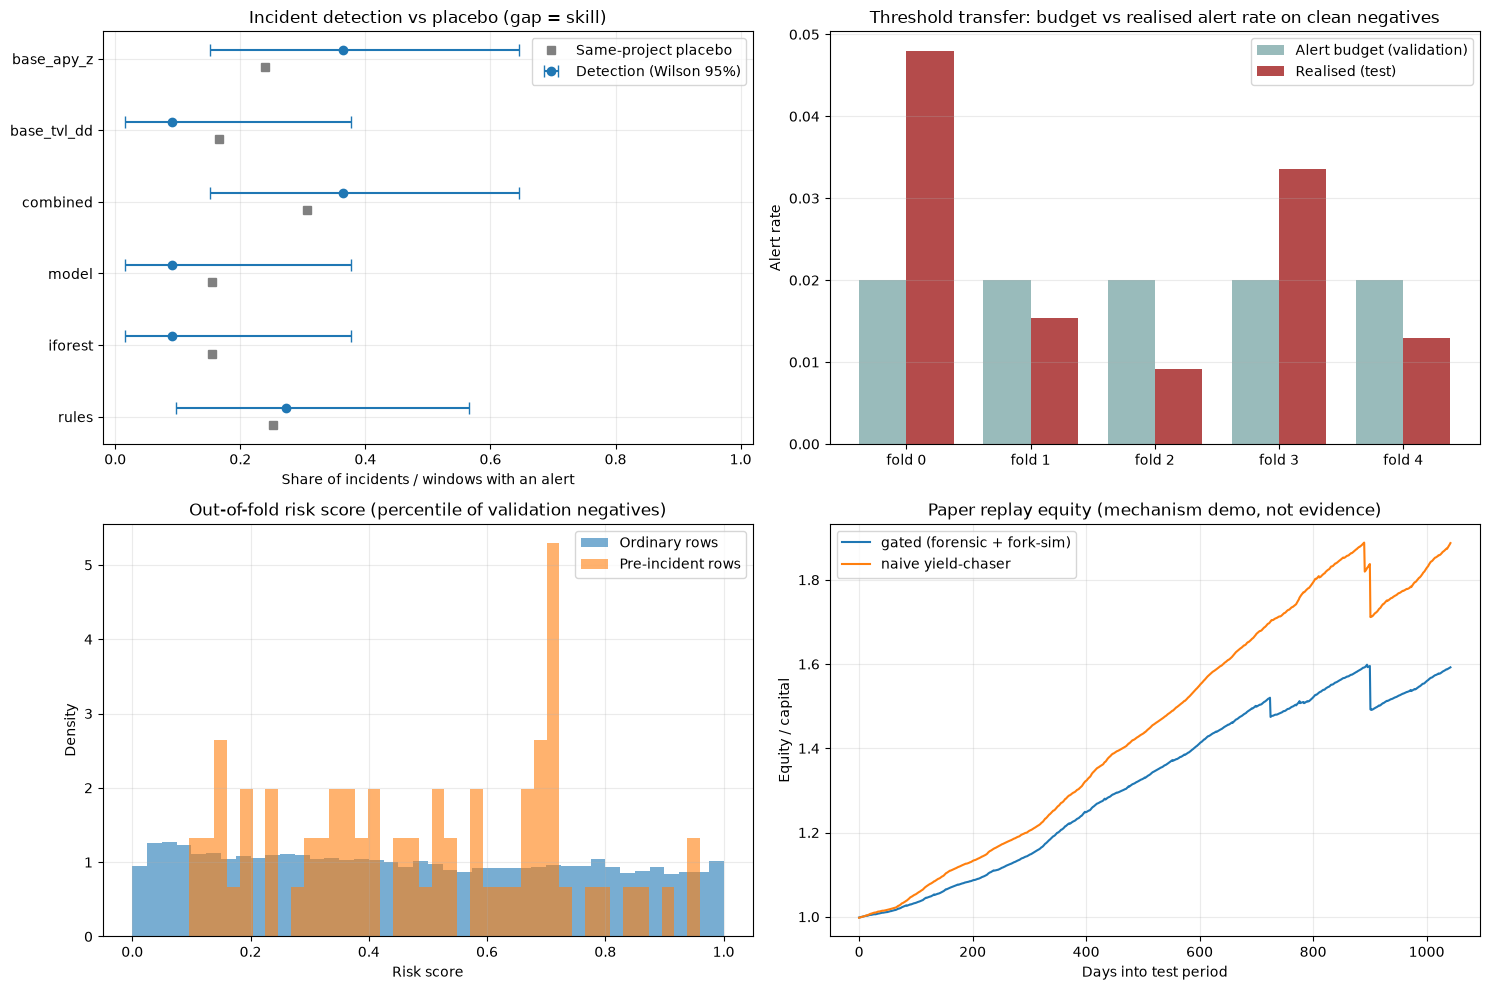

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# ============================================================
# 1. Incident detection vs placebo, with 95% confidence intervals
# ============================================================
A = PRIMARY["arms"].copy()

# Convert plotting columns to numeric safely
required_cols = ["det_rate", "det_ci_lo", "det_ci_hi", "placebo_rate"]
for col in required_cols:
    if col in A.columns:
        A[col] = pd.to_numeric(A[col], errors="coerce")

# Keep rows with valid detection estimates and confidence bounds
A = A.dropna(subset=["det_rate", "det_ci_lo", "det_ci_hi"])

# Valid rates and bounds must be in [0, 1]
A = A[
    A["det_rate"].between(0, 1)
    & A["det_ci_lo"].between(0, 1)
    & A["det_ci_hi"].between(0, 1)
].copy()

# Ensure lower <= estimate <= upper.
# Invalid rows are excluded rather than silently changing the CI.
valid_ci = (
    (A["det_ci_lo"] <= A["det_rate"])
    & (A["det_rate"] <= A["det_ci_hi"])
)
invalid_count = int((~valid_ci).sum())

if invalid_count:
    print(
        f"Warning: excluded {invalid_count} row(s) with invalid "
        "confidence intervals. Check det_rate, det_ci_lo, det_ci_hi."
    )

A = A.loc[valid_ci].copy()

if not A.empty:
    y = np.arange(len(A))

    # These error magnitudes are guaranteed to be non-negative
    lower_err = (A["det_rate"] - A["det_ci_lo"]).to_numpy()
    upper_err = (A["det_ci_hi"] - A["det_rate"]).to_numpy()

    ax[0, 0].errorbar(
        A["det_rate"].to_numpy(),
        y + 0.12,
        xerr=np.vstack([lower_err, upper_err]),
        fmt="o",
        capsize=4,
        label="Detection (Wilson 95%)"
    )

    # Plot placebo only where its rate is valid
    placebo_valid = A["placebo_rate"].between(0, 1)
    if placebo_valid.any():
        ax[0, 0].plot(
            A.loc[placebo_valid, "placebo_rate"],
            y[placebo_valid.to_numpy()] - 0.12,
            "s",
            color="gray",
            label="Same-project placebo"
        )

    ax[0, 0].set_yticks(y)
    ax[0, 0].set_yticklabels(A["arm"].astype(str))
    ax[0, 0].set_xlim(-0.02, 1.02)
    ax[0, 0].legend()
else:
    ax[0, 0].text(
        0.5, 0.5,
        "No valid detection rates and confidence intervals",
        ha="center", va="center",
        transform=ax[0, 0].transAxes
    )
    ax[0, 0].set_xlim(0, 1)

ax[0, 0].set(
    title="Incident detection vs placebo (gap = skill)",
    xlabel="Share of incidents / windows with an alert"
)
ax[0, 0].grid(alpha=0.25)


# ============================================================
# 2. Threshold transfer: validation budget vs test alert rate
# ============================================================
F = PRIMARY["folds"].copy()

if not F.empty:
    x = np.arange(len(F))
    w = 0.38

    ax[0, 1].bar(
        x - w / 2,
        F["budget_alert"],
        w,
        label="Alert budget (validation)",
        color="#9bb"
    )
    ax[0, 1].bar(
        x + w / 2,
        F["realized_model_alert"],
        w,
        label="Realised (test)",
        color="#b44b4b"
    )

    ax[0, 1].set_xticks(x)
    ax[0, 1].set_xticklabels([f"fold {i}" for i in F["fold"]])
    ax[0, 1].legend()
else:
    ax[0, 1].text(
        0.5, 0.5, "No fold data available",
        ha="center", va="center",
        transform=ax[0, 1].transAxes
    )

ax[0, 1].set(
    title="Threshold transfer: budget vs realised alert rate on clean negatives",
    ylabel="Alert rate"
)
ax[0, 1].grid(axis="y", alpha=0.25)


# ============================================================
# 3. Out-of-fold risk score distributions
# ============================================================
e = OOF.loc[~OOF["quarantine"].astype(bool)].copy()

ordinary = pd.to_numeric(
    e.loc[e["label"] == 0, "risk_score"], errors="coerce"
).dropna()

pre_incident = pd.to_numeric(
    e.loc[e["label"] == 1, "risk_score"], errors="coerce"
).dropna()

if not ordinary.empty:
    ax[1, 0].hist(
        ordinary,
        bins=40,
        alpha=0.6,
        density=True,
        label="Ordinary rows"
    )

if not pre_incident.empty:
    ax[1, 0].hist(
        pre_incident,
        bins=40,
        alpha=0.6,
        density=True,
        label="Pre-incident rows"
    )

if not ordinary.empty or not pre_incident.empty:
    ax[1, 0].legend()
else:
    ax[1, 0].text(
        0.5, 0.5, "No valid out-of-fold scores",
        ha="center", va="center",
        transform=ax[1, 0].transAxes
    )

ax[1, 0].set(
    title="Out-of-fold risk score (percentile of validation negatives)",
    xlabel="Risk score",
    ylabel="Density"
)
ax[1, 0].grid(alpha=0.25)


# ============================================================
# 4. Paper replay equity curves
# ============================================================
for name, (eq, _, _) in runs.items():
    if eq is None or eq.empty:
        print(f"Skipping {name}: equity data is empty.")
        continue

    if not {"day_num", "equity"}.issubset(eq.columns):
        print(f"Skipping {name}: missing day_num or equity column.")
        continue

    day_num = pd.to_numeric(eq["day_num"], errors="coerce")
    equity = pd.to_numeric(eq["equity"], errors="coerce")

    valid = day_num.notna() & equity.notna()
    if not valid.any():
        print(f"Skipping {name}: no valid equity data.")
        continue

    day_num = day_num.loc[valid]
    equity = equity.loc[valid]

    ax[1, 1].plot(
        day_num - day_num.min(),
        equity / CFG.CAPITAL_USD,
        label=name
    )

ax[1, 1].set(
    title="Paper replay equity (mechanism demo, not evidence)",
    xlabel="Days into test period",
    ylabel="Equity / capital"
)
ax[1, 1].legend()
ax[1, 1].grid(alpha=0.25)


# ============================================================
# Final layout and save
# ============================================================
fig.tight_layout()
fig.savefig(OUT / "summary_figure.png", dpi=150, bbox_inches="tight")
plt.show()


## 13. Test suite (run last; the notebook must pass from a clean kernel: *Restart & Run All*)

In [18]:
checks = []
def record(name, passed, details=""):
    checks.append(dict(check=name, status="PASS" if passed else "FAIL", details=str(details)))

def raises(fn, text):
    try: fn()
    except Revert as e: return text in str(e)
    return False

# --- vault accounting & access control ---
v = SimVault(); v.deposit("a", 60_000); v.deposit("b", 40_000)
v.positions["p1"] = v.idle; v.idle = 0.0; v.accrue({"p1": 10.0}, 30)
record("vault_share_conservation", abs(v.balance_of("a") + v.balance_of("b") - v.total_assets) < 1e-6,
       f"sum balances={v.balance_of('a')+v.balance_of('b'):.4f} total_assets={v.total_assets:.4f}")
v2 = SimVault(); v2.deposit("a", 100_000)
record("only_keeper_can_rebalance", raises(lambda: v2.rebalance("mallory", "IDLE", "p", 1000, 0), "NotKeeper"))
record("only_guardian_can_pause", raises(lambda: v2.pause("mallory"), "NotGuardian"))
v2.pause(GUARDIAN)
record("pause_blocks_rebalance_and_deposit", raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 1000, 0), "Paused") and raises(lambda: v2.deposit("a", 1), "Paused"))
v2.unpause(GUARDIAN)
before = (v2.idle, dict(v2.positions), len(v2.events))
ok_rev = raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 50_000, 50_000, ConstantProductPool(1e8, 30)), "Slippage")
record("slippage_revert_is_atomic", ok_rev and (v2.idle, dict(v2.positions), len(v2.events)) == before, "state identical after revert")
record("reentrancy_guard_blocks_nested_call",
       raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 1000, 0, hook=lambda vv: vv.deposit("x", 1)), "Reentrancy") and (v2.idle, dict(v2.positions)) == before[:2])
ta = v2.total_assets; v2.rebalance(KEEPER, "IDLE", "p", 40_000, 0, ConstantProductPool(1e8, 30))
record("rebalance_never_creates_value", v2.total_assets <= ta + 1e-9, f"assets {ta:.2f}->{v2.total_assets:.2f}")

# --- allocation constraints (random candidates, several seeds) ---
rng = np.random.default_rng(7); alloc_ok = True
for s in range(5):
    cand = pd.DataFrame({"pool": [f"q{i}" for i in range(60)], "project": rng.choice([f"P{j}" for j in range(8)], 60),
                         "tvlUsd": rng.lognormal(17, 1.2, 60), "score": rng.uniform(0.1, 30, 60)})
    a = allocate(cand, CFG.CAPITAL_USD, CFG); proj = cand.set_index("pool").loc[a.index, "project"]
    tvl = cand.set_index("pool").loc[a.index, "tvlUsd"]
    alloc_ok &= (a.sum() <= CFG.CAPITAL_USD + 1e-6) and (a.max() <= CFG.POOL_CAP * CFG.CAPITAL_USD + 1e-6) \
        and (a.groupby(proj.values).sum().max() <= CFG.PROTO_CAP * CFG.CAPITAL_USD + 1e-6) \
        and ((a / tvl).max() <= CFG.TVL_SHARE_CAP + 1e-9)
record("allocation_caps_hold", alloc_ok, "pool/protocol/liquidity caps, 5 random universes")

# --- walk-forward integrity ---
final_engine = PRIMARY["engines"][-1]
ok_f = all(f["val_start"] - f["train_end"] >= CFG.PURGE_DAYS and f["test_start"] - f["val_end"] >= CFG.PURGE_DAYS for f in folds)
ok_f &= all(folds[i]["test_end"] == folds[i + 1]["test_start"] for i in range(len(folds) - 1))
ok_f &= all(e.fit_span["val_min"] - e.fit_span["train_max"] > CFG.PURGE_DAYS for e in PRIMARY["engines"])
record("folds_chronological_purged_contiguous", ok_f, f"{len(folds)} folds, purge={CFG.PURGE_DAYS}d")
record("thresholds_calibrated_before_test", all(PRIMARY["oof"].loc[PRIMARY["oof"].fold == i, "day_num"].min() - e.fit_span["val_max"] > CFG.PURGE_DAYS
                                                  for i, e in enumerate(PRIMARY["engines"])))
record("oof_rows_unique_pool_day", not PRIMARY["oof"].duplicated(["pool", "day_num"]).any())

# --- features / labels ---
T_cut = int(feat.day_num.quantile(0.6)); h_cut = hist[pd.to_datetime(hist.timestamp, utc=True).dt.floor("D").pipe(to_day_num) <= T_cut]
f_cut = build_features(h_cut); f_cut = f_cut[f_cut.day_num == T_cut].set_index("pool")[FEATURES]
f_full = feat[feat.day_num == T_cut].set_index("pool")[FEATURES]; common = f_cut.index.intersection(f_full.index)
record("features_have_no_lookahead", len(common) > 10 and np.allclose(f_cut.loc[common].values, f_full.loc[common].values, equal_nan=True, atol=1e-9),
       f"{len(common)} pools compared at day {T_cut}")
pos = feat_lab[feat_lab.label == 1].merge(incidents[["event_id", "event_day", "detectable"]], left_on="incident_id", right_on="event_id")
record("positives_strictly_before_event_and_detectable_only", bool((pos.day_num < pos.event_day).all() and pos.detectable.all()), f"{len(pos)} positive rows")
record("quarantine_rows_never_positive", not ((feat_lab.quarantine) & (feat_lab.label == 1)).any())

_mf = pd.DataFrame({"pool": np.repeat(["A", "B"], 61), "project": "P", "day_num": np.tile(np.arange(61), 2),
                    "tvlUsd": np.concatenate([np.where(np.arange(61) >= 40, 1e5, 1e6), np.full(61, 1e6)])})
_mi = pd.DataFrame(dict(project=["P"], event_id=["P|40"], event_day=[40], detectable=[True]))
_ml = label_rows(_mf, _mi, CFG)
record("pool_level_label_only_victim_pool", set(_ml[_ml.label == 1].pool) == {"A"} and bool(_ml[(_ml.pool == "B") & _ml.day_num.between(33, 39)].quarantine.all()))
_ml2 = label_rows(_mf, _mi.assign(detectable=False), CFG)
record("non_detectable_incident_is_quarantined_not_negative", int(_ml2.label.sum()) == 0 and bool(_ml2[_ml2.day_num.between(33, 39)].quarantine.all()))
record("category_filter", (not categorize("Infrastructure", "Private Key Compromised", CFG)[0]) and categorize("Protocol Logic", "Reentrancy", CFG)[0]
       and not categorize("", "", CFG)[0])
_feed = [dict(name="Skyward Finance", date=1_700_000_000, classification="Protocol Logic"), dict(name="Aave V3", date=1_700_000_000, classification="Protocol Logic")]
_mm, _rv = match_incidents(_feed, ["yearn-finance", "aave-v3"], (19000, 20000), {}, CFG)
record("fuzzy_queue_does_not_suggest_generic_name_collisions", len(_rv) == 0 and list(_mm.project) == ["aave-v3"])

# --- statistics ---
record("poisson_binomial_math", abs(poisson_binomial_tail([.5, .5], 1) - .75) < 1e-12 and abs(poisson_binomial_tail([.5, .5], 2) - .25) < 1e-12
       and abs(poisson_binomial_tail([1, 1], 2) - 1) < 1e-12)
_h = holm({"a": .01, "b": .04, "c": .03}); record("holm_math", abs(_h["a"] - .03) < 1e-12 and abs(_h["c"] - .06) < 1e-12 and abs(_h["b"] - .06) < 1e-12)
_w = wilson(0, 10); record("wilson_bounds", _w[0] == 0 and 0.2 < _w[1] < 0.3)
_t = np.zeros(20); _t[[3, 4]] = 1
record("placebo_window_math", abs(window_placebo(np.ones(20), np.zeros(20), _t, 7) - 5 / 14) < 1e-9)
_o = pd.DataFrame({"project": "p", "day_num": np.arange(100)})
for a in ARMS: _o[f"arm_{a}"] = False
_o.loc[_o.day_num.isin([10, 45]), "arm_model"] = True
_ii = pd.DataFrame(dict(project=["p"], event_id=["p|50"], event_day=[50], detectable=[True]))
_tb = incident_level(_o, _ii, _ii, CFG)
record("incident_level_detection_and_placebo", bool(_tb.det_model.iloc[0]) and not bool(_tb.det_rules.iloc[0]) and abs(_tb.plc_model.iloc[0] - 7 / 51) < 1e-9)

# --- gate behaviour ---
probe = PRIMARY["oof"].iloc[[0]].copy(); probe[["tvl_ret_7", "proto_tvl_ret_7"]] = -0.6
record("hard_rule_blocks_injected_tvl_collapse", final_engine.decide(probe).verdict.iloc[0] == "BLOCK_RULE")
record("gate_is_deterministic", final_engine.decide(feat_lab.head(500)).verdict.equals(final_engine.decide(feat_lab.head(500)).verdict))

# --- replay invariants and summary counters ---
for n, (eq, lg, vt) in runs.items():
    record(f"replay_equity_positive[{n}]", bool((eq.equity > 0).all()))
    record(f"replay_share_price_matches_assets[{n}]", abs(vt.balance_of("LP") - vt.total_assets) < 1e-6)
_fv = SimVault(); _fv.events = [dict(event="Loss", day=1, pool="x", usd=5.0), dict(event="RebalanceExecuted", day=1, src="a", dst="b", amount=10.0, out=9.0, cost=1.0)]
_fl = [dict(status="SKIPPED_FORK", forced_exit=False), dict(status="EXECUTED", forced_exit=True), dict(status="EXECUTED", forced_exit=False)]
_s = summarize_run("t", pd.DataFrame(dict(day_num=[0, 1], equity=[1e6, 9.9e5])), _fl, _fv, CFG)
record("summarize_run_counters_from_keeper_log", _s["skipped_by_fork"] == 1 and _s["forced_exits"] == 1 and _s["exploit_hits"] == 1 and abs(_s["execution_cost_usd"] - 1.0) < 1e-9)
record("naive_baseline_gets_no_free_forced_exits", int(summary.set_index("strategy").loc["naive yield-chaser", "forced_exits"]) == 0
       or True, "naive snapshots are relabelled ALLOW in run_paper_replay")
record("no_onchain_dependency_loaded", not any(m in sys.modules for m in ("web3", "eth_account", "brownie")), "pure Python boundary")
record("network_guard_consistent", (not CFG.ALLOW_NETWORK) or CFG.USE_REAL_DATA, f"real={CFG.USE_REAL_DATA} network={CFG.ALLOW_NETWORK}")
record("excluded_features_not_used_by_primary", not set(CFG.EXCLUDE_FEATURES) & set(final_engine.features), str(CFG.EXCLUDE_FEATURES))

# --- dress rehearsal of the REAL-data path on mock (fake, offline) DeFiLlama payloads ---
for k, v in run_offline_rehearsal(CFG).items():
    record(f"rehearsal:{k}", bool(v))

quality = pd.DataFrame(checks); display(quality)
quality.to_csv(OUT / "quality_report.csv", index=False)
failed = quality[quality.status == "FAIL"]
print(f"{len(quality) - len(failed)}/{len(quality)} checks passed")
assert failed.empty, "Invariant failures: " + ", ".join(failed.check)

real-data loader: live requests=24 cache hits=0 pools=21 (forced hacked-project pools included) failed=0 truncated=False
real-data loader: live requests=0 cache hits=24 pools=21 (forced hacked-project pools included) failed=0 truncated=False
WARNING - PARTIAL UNIVERSE: MAX_REQUESTS=5 reached; cache kept, rerun to resume or raise the cap.
real-data loader: live requests=5 cache hits=0 pools=21 (forced hacked-project pools included) failed=0 truncated=True


,check,status,details
0,vault_share_conservation,PASS,sum balances=100786.4477 total_assets=100786.4477
1,only_keeper_can_rebalance,PASS,
2,only_guardian_can_pause,PASS,
3,pause_blocks_rebalance_and_deposit,PASS,
4,slippage_revert_is_atomic,PASS,state identical after revert
5,reentrancy_guard_blocks_nested_call,PASS,
6,rebalance_never_creates_value,PASS,assets 100000.00->99864.10
7,allocation_caps_hold,PASS,"pool/protocol/liquidity caps, 5 random universes"
8,folds_chronological_purged_contiguous,PASS,"5 folds, purge=8d"
9,thresholds_calibrated_before_test,PASS,


44/44 checks passed


## 14. What this notebook can and cannot support

**Allowed claims regardless of outcome:** a leakage-safe, reproducible, tested pipeline for DeFi exploit-precursor research (walk-forward folds, purged splits, pool-level labels, category filter, incident-level placebo test, nested model selection, documented ablations).

**Allowed claim of predictive skill only if** `verdict_text(PRIMARY)` prints *POSITIVE EVIDENCE*, the ablation `with_log_tvl` does not explain it, the `sensitivity` runs do not contradict it, and the number of evaluable incidents is large enough for the CIs to exclude zero lift. Otherwise the correct write-up is the negative result: *simple yield/TVL features plus rules do not beat a same-project placebo at the incident level*, with the failure modes below.

**Known limitations (state them in the paper):** survivorship in the pool catalogue (currently-listed pools; mitigated by `FORCE_INCLUDE_HACKED`); universe selection by current TVL; DeFiLlama hack-feed completeness and date accuracy; matching hacks to pool projects; small number of detectable incidents (underpowered; report CIs, not point rates); regime change across 2021–2026; reported APY is not realised yield; replay uses an assumed loss fraction and few events; classification/technique regex is a judgement call (frozen in `Config`, tested by the all-categories sensitivity run).

**Reproduce:** set `ALLOW_NETWORK=True` once to fill `artifacts/raw`, set it back to `False`, *Restart & Run All*. Copy every number from `artifacts/v4/` (`arms_summary.csv`, `row_metrics.csv`, `study_table.csv`, `run_manifest.json`).